# HITL-IoT v1.1 — Reproducible Descriptive Characterisation and Benchmark Verification

**Notebook:** `02_HITL-IoT_v1.1_Descriptive_Analysis.ipynb`

## Purpose and Scope

This notebook is the single reproducible source for every descriptive statistic, **Tables 2–6**, and **Figures 3–6** of the revised HITL-IoT manuscript. It:

1. verifies by SHA-256 that the frozen, canonical HITL-IoT v1.1 release is being analysed;
2. audits the manuscript-relevant variables and their permitted roles;
3. computes all descriptive statistics directly from the released CSV files;
4. regenerates the manuscript tables and figures and exports every value to CSV/JSON.

**Scope limits.** All records in HITL-IoT v1.1 are *generated* by a documented, seeded generator. The oversight fields are properties of **configured oversight profiles**; they are not observations of security analysts. Nothing in this notebook establishes operational traffic realism, empirical analyst behaviour, or regulatory compliance. No intrusion-detection model is trained here — Track-1 model training belongs to a separate benchmark notebook.

**Suggested mapping to the manuscript** (adjust numbering if the manuscript differs):

| Manuscript item | Source in this notebook |
|---|---|
| Table 2 | `device_distribution.csv` |
| Table 3 | `attack_distribution.csv` |
| Table 4 | `oversight_profile_configuration.csv` + `oversight_profile_performance.csv` |
| Table 5 | `continuous_statistics.csv` (core flow features) |
| Table 6 | `full_vs_oversight.csv` |
| Figures 3–6 | `analysis_v1.1/figures/` |

## 1. Imports and Configuration

Only standard scientific Python packages are used. Paths are relative. The notebook finds the frozen files in `data/v1.1/` (repository layout, run from the repository root or `notebooks/`) or in a `release_v1.1/` folder.

In [1]:
from pathlib import Path
import hashlib
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter, MaxNLocator
from scipy import stats
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# Locate the frozen v1.1 files: repository layout (data/v1.1) or the original release_v1.1/ folder.
_CANDIDATES = [Path("data/v1.1"), Path("../data/v1.1"), Path("release_v1.1"), Path("../release_v1.1"),
               Path("/kaggle/input/hitl-iot-human-in-the-loop-iot-ids-dataset")]
RELEASE_DIR = next((p for p in _CANDIDATES if (p / "HITL-IoT_dataset_v1.1.csv").is_file()), None)
if RELEASE_DIR is None:
    raise FileNotFoundError("HITL-IoT v1.1 CSVs not found. Run `python scripts/download_release_assets.py` "
                            "from the repository root, or place the files in data/v1.1/.")
OUT_DIR = Path("analysis_v1.1")
DIRS = {name: OUT_DIR / name for name in ("tables", "figures", "manuscript_values", "audit")}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

VERSION = "v1.1"
FILES = {
    "dataset": RELEASE_DIR / f"HITL-IoT_dataset_{VERSION}.csv",
    "oversight": RELEASE_DIR / f"HITL-IoT_oversight_subset_{VERSION}.csv",
    "schema_json": RELEASE_DIR / f"HITL-IoT_schema_{VERSION}.json",
    "feature_policy": RELEASE_DIR / f"HITL-IoT_feature_policy_{VERSION}.json",
    "splits": RELEASE_DIR / f"HITL-IoT_splits_{VERSION}.csv",
    "summary": RELEASE_DIR / f"HITL-IoT_summary_{VERSION}.json",
    "manifest": RELEASE_DIR / f"HITL-IoT_manifest_{VERSION}.json",
    "checksums": RELEASE_DIR / f"HITL-IoT_checksums_{VERSION}.txt",
    "config": RELEASE_DIR / f"HITL-IoT_config_{VERSION}.json",
}
EXPECTED_DEVICES = {"camera", "thermostat", "speaker", "doorbell", "tv"}
PROFILE_ORDER = ["high_competence", "medium_competence", "low_competence"]
TABLES_WRITTEN: list[Path] = []
print("Release directory:", RELEASE_DIR.resolve())
print("Output directory :", OUT_DIR.resolve())

Release directory: /home/claude/nbwork/release_v1.1
Output directory : /home/claude/nbwork/analysis_v1.1


### 1.1 Helper functions

Reusable helpers for hashing, descriptive statistics, percentage tables and table export. Every exported table is registered so that its existence can be verified at the end.

In [2]:
def sha256_of(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def describe_numeric(x: pd.Series) -> dict:
    # N, mean, median, SD, Q1, Q3, IQR, min, max for a numeric series (NaN excluded).
    x = pd.to_numeric(x, errors="coerce").dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    return {"N": int(x.size), "mean": x.mean(), "median": x.median(), "sd": x.std(ddof=1),
            "Q1": q1, "Q3": q3, "IQR": q3 - q1, "min": x.min(), "max": x.max()}


def count_pct(s: pd.Series, name: str, denominator: int | None = None) -> pd.DataFrame:
    # Count and percentage table for a categorical series, sorted by count (descending).
    vc = s.value_counts(dropna=False)
    denom = denominator if denominator is not None else int(vc.sum())
    out = vc.rename_axis(name).reset_index(name="count")
    out["percent"] = 100 * out["count"] / denom
    return out


def save_table(df: pd.DataFrame, filename: str, subdir: str = "tables") -> Path:
    path = DIRS[subdir] / filename
    df.to_csv(path, index=False, float_format="%.6g")
    TABLES_WRITTEN.append(path)
    return path


def fmt_table(df: pd.DataFrame, pct_cols=(), int_cols=(), dec=3):
    # Display-only formatting (exports keep full precision).
    fmt = {c: "{:,.0f}" for c in int_cols}
    fmt.update({c: "{:.2f}%" for c in pct_cols})
    for c in df.select_dtypes("number").columns:
        fmt.setdefault(c, "{:,.%df}" % dec)
    return df.style.format(fmt).hide(axis="index")


def to_records(df: pd.DataFrame, key: str) -> dict:
    # Convert a table to {key_value: {col: value}} with JSON-safe Python scalars.
    rec = {}
    for _, row in df.iterrows():
        rec[str(row[key])] = {c: (None if pd.isna(v) else (v.item() if hasattr(v, "item") else v))
                              for c, v in row.items() if c != key}
    return rec

### 1.2 Publication figure style

One style system is defined here and applied to every manuscript figure: a journal sans-serif font (Arial → Helvetica → Liberation Sans → DejaVu Sans fallback), 7.5–10 pt text at final size, minimal spines, subtle horizontal grids, and a restrained colour-blind-safe palette (Okabe–Ito-derived). Each semantic role keeps the same colour in every figure, and colour is always paired with a second cue (hatch, line style or direct label) so that figures remain readable in greyscale.

In [3]:
SINGLE_COL = 3.5   # inches
DOUBLE_COL = 7.16  # inches

COLORS = {
    "benign": "#0072B2",        # blue
    "attack": "#D55E00",        # vermillion
    "full": "#8C8C8C",          # mid grey
    "oversight": "#1F1F1F",     # near-black
    "high_competence": "#1B4F5C",
    "medium_competence": "#4D8FA0",
    "low_competence": "#A9CFD8",
    "neutral": "#4D4D4D",
    "grid": "#E3E3E3",
}
SPLIT_COLORS = {"train": "#D9E4EC", "validation": "#A9C4D6", "test": "#6F97B3"}
PROFILE_LABELS = {"high_competence": "High", "medium_competence": "Medium", "low_competence": "Low"}
LINESTYLES = {"full": "-", "oversight": "--"}
HATCH_ATTACK = "////"
CORR_CMAP = LinearSegmentedColormap.from_list(
    "div_blue_orange", ["#2B5C8A", "#8FB3D0", "#F7F7F7", "#E7A77E", "#B3441B"])


def set_publication_style() -> None:
    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
        "font.size": 8.5, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
        "legend.fontsize": 8, "legend.frameon": False, "legend.handlelength": 1.6,
        "axes.linewidth": 0.6, "axes.edgecolor": "#333333", "axes.labelcolor": "#1A1A1A",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COLORS["grid"], "grid.linewidth": 0.5,
        "xtick.major.width": 0.6, "ytick.major.width": 0.6,
        "xtick.major.size": 2.5, "ytick.major.size": 2.5,
        "xtick.color": "#333333", "ytick.color": "#333333",
        "lines.linewidth": 1.2, "patch.linewidth": 0.5,
        "figure.dpi": 110, "savefig.dpi": 600,
        "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
        "axes.formatter.use_mathtext": False, "axes.formatter.limits": (-5, 6),
    })


def ygrid(ax, axis="y"):
    ax.grid(True, axis=axis, color=COLORS["grid"], linewidth=0.5)
    ax.set_axisbelow(True)


def panel_label(ax, letter: str, x: float = -0.14, y: float = 1.04) -> None:
    ax.text(x, y, f"({letter})", transform=ax.transAxes, fontsize=10.5,
            fontweight="bold", va="bottom", ha="left")


thousands = FuncFormatter(lambda v, _: f"{v:,.0f}")
FIGURE_REGISTRY: dict[str, dict] = {}


def save_publication_figure(fig, stem: str, caption: str) -> dict:
    # Save PDF + SVG (vector, authoritative) and PNG (600 dpi); record axis labels for QC.
    paths = {}
    for ext, kw in (("pdf", {}), ("svg", {}), ("png", {"dpi": 600})):
        p = DIRS["figures"] / f"{stem}.{ext}"
        fig.savefig(p, bbox_inches="tight", pad_inches=0.03, **kw)
        paths[ext] = p
    fig.canvas.draw()
    axes_info = [{"xlabel": a.get_xlabel(), "ylabel": a.get_ylabel(),
                  "xticklabels": [t.get_text() for t in a.get_xticklabels() if t.get_text()],
                  "yticklabels": [t.get_text() for t in a.get_yticklabels() if t.get_text()],
                  "texts": [t.get_text() for t in a.texts]} for a in fig.axes if a.get_label() != "<colorbar>"]
    FIGURE_REGISTRY[stem] = {"paths": paths, "caption": caption, "axes": axes_info,
                             "size_in": tuple(np.round(fig.get_size_inches(), 2))}
    return paths


set_publication_style()
print("Font resolved to:", mpl.font_manager.FontProperties(family=mpl.rcParams["font.sans-serif"]).get_name())

Font resolved to: Liberation Sans


## 2. Canonical Release Verification

Filenames are not trusted. The SHA-256 of each authoritative artefact is recomputed and compared with `HITL-IoT_checksums_v1.1.txt`. Execution stops if the dataset (or any other required artefact) does not match.

In [4]:
missing = [str(p) for p in FILES.values() if not p.is_file()]
assert not missing, f"Required release files are missing: {missing}"

expected = {}
for line in FILES["checksums"].read_text(encoding="utf-8").splitlines():
    line = line.strip()           # strips Windows CR as well
    if line:
        digest, fname = line.split(maxsplit=1)
        expected[fname.strip()] = digest.lower()

verify_keys = ["dataset", "oversight", "schema_json", "feature_policy", "splits", "summary", "manifest", "config"]
rows = []
for k in verify_keys:
    p = FILES[k]
    obs = sha256_of(p)
    exp = expected.get(p.name)
    rows.append({"File": p.name, "Expected SHA-256": exp, "Observed SHA-256": obs,
                 "Match": exp is not None and exp == obs})
generator = RELEASE_DIR / "hitl_iot_generator_v1_1.py"
if generator.is_file():
    obs = sha256_of(generator)
    rows.append({"File": generator.name, "Expected SHA-256": expected.get(generator.name),
                 "Observed SHA-256": obs, "Match": expected.get(generator.name) == obs})
source_verification = pd.DataFrame(rows)
save_table(source_verification, "source_verification.csv", "audit")

ds_row = source_verification.loc[source_verification.File == FILES["dataset"].name].iloc[0]
assert ds_row["Match"], (f"Dataset hash mismatch: expected {ds_row['Expected SHA-256']}, "
                         f"observed {ds_row['Observed SHA-256']}. Wrong or modified release.")
assert source_verification["Match"].all(), "One or more authoritative artefacts fail SHA-256 verification."
SOURCE_VERIFIED = True

manifest = json.loads(FILES["manifest"].read_text(encoding="utf-8"))
print(f"Release: {manifest['dataset_name']} {manifest['version']} | seed {manifest['seed']} | "
      f"publication_ready={manifest.get('publication_ready')} | generated on {manifest['environment']}")
source_verification.assign(**{"Expected SHA-256": source_verification["Expected SHA-256"].str[:16] + "…",
                              "Observed SHA-256": source_verification["Observed SHA-256"].str[:16] + "…"})

Release: HITL-IoT 1.1 | seed 42 | publication_ready=True | generated on {'python': '3.12.7', 'platform': 'Windows-11-10.0.26200-SP0', 'numpy': '1.26.4', 'pandas': '2.2.2'}


,File,Expected SHA-256,Observed SHA-256,Match
0,HITL-IoT_dataset_v1.1.csv,c6dd623029f6ca09…,c6dd623029f6ca09…,True
1,HITL-IoT_oversight_subset_v1.1.csv,58fc268325fcbc56…,58fc268325fcbc56…,True
2,HITL-IoT_schema_v1.1.json,7967ffa9a8ac51d6…,7967ffa9a8ac51d6…,True
3,HITL-IoT_feature_policy_v1.1.json,0666306f134fabe2…,0666306f134fabe2…,True
4,HITL-IoT_splits_v1.1.csv,6a0c19d3c957b92f…,6a0c19d3c957b92f…,True
5,HITL-IoT_summary_v1.1.json,c14f091cc997f40c…,c14f091cc997f40c…,True
6,HITL-IoT_manifest_v1.1.json,29d220e832697c38…,29d220e832697c38…,True
7,HITL-IoT_config_v1.1.json,a3262da1299493f7…,a3262da1299493f7…,True
8,hitl_iot_generator_v1_1.py,08e3914deeef5b74…,08e3914deeef5b74…,True


### 2.1 Load the release and validate the schema

Counts are never assumed; they are computed from the CSV files. The checks below confirm required columns, unique flow identifiers, the five-device taxonomy, the twelve attack families, and consistency between the full dataset and the oversight-subset file.

In [5]:
df = pd.read_csv(FILES["dataset"], low_memory=False)
ov = pd.read_csv(FILES["oversight"], low_memory=False)
splits = pd.read_csv(FILES["splits"])
schema = pd.DataFrame(json.loads(FILES["schema_json"].read_text(encoding="utf-8")))
policy = json.loads(FILES["feature_policy"].read_text(encoding="utf-8"))
summary = json.loads(FILES["summary"].read_text(encoding="utf-8"))
config = json.loads(FILES["config"].read_text(encoding="utf-8"))

for frame in (df, ov, splits):
    frame["timestamp"] = pd.to_datetime(frame["timestamp"])

REQUIRED = ["flow_id", "timestamp", "device_type", "protocol", "service_category", "port_expected_for_device",
            "dst_category", "is_attack", "attack_type", "generated_attack_score", "generated_prediction",
            "ambiguity_score", "oversight_selected", "oversight_profile", "profile_decision",
            "profile_confidence", "generated_decision_latency", "model_profile_agreement", "profile_rationale"]
schema_checks = []
def schema_check(name, cond, detail=""):
    schema_checks.append({"check": name, "result": "PASS" if cond else "FAIL", "detail": detail})

schema_check("required columns in dataset", set(REQUIRED) <= set(df.columns), str(sorted(set(REQUIRED) - set(df.columns))))
schema_check("required columns in oversight subset", set(REQUIRED) <= set(ov.columns), str(sorted(set(REQUIRED) - set(ov.columns))))
schema_check("unique flow_id", df["flow_id"].is_unique)
schema_check("exactly five device types", set(df["device_type"]) == EXPECTED_DEVICES, str(sorted(df["device_type"].unique())))
schema_check("no Mixed/Unknown/Other device", not ({"mixed", "unknown", "other"} & {d.lower() for d in df["device_type"].unique()}))
n_attack_families = df.loc[df["is_attack"], "attack_type"].nunique()
schema_check("exactly twelve attack families", n_attack_families == 12, str(n_attack_families))
schema_check("no 'normal' label among attacks", "normal" not in set(df.loc[df["is_attack"], "attack_type"]))
schema_check("oversight file size == oversight_selected rows", len(ov) == int(df["oversight_selected"].sum()),
             f"{len(ov)} vs {int(df['oversight_selected'].sum())}")
schema_check("oversight file flow_ids match selected rows", set(ov["flow_id"]) == set(df.loc[df["oversight_selected"], "flow_id"]))
schema_check("every column documented in schema", set(df.columns) <= set(schema["field"]))
schema_check("split file covers every flow once", splits["flow_id"].is_unique and set(splits["flow_id"]) == set(df["flow_id"]))
schema_checks = pd.DataFrame(schema_checks)
assert (schema_checks["result"] == "PASS").all(), schema_checks[schema_checks.result == "FAIL"]
N = len(df)
print(f"Loaded {N:,} flows × {df.shape[1]} columns; oversight subset {len(ov):,} rows.")
schema_checks

Loaded 127,845 flows × 60 columns; oversight subset 10,227 rows.


,check,result,detail
0,required columns in dataset,PASS,[]
1,required columns in oversight subset,PASS,[]
2,unique flow_id,PASS,
3,exactly five device types,PASS,"['camera', 'doorbell', 'speaker', 'thermostat'..."
4,no Mixed/Unknown/Other device,PASS,
5,exactly twelve attack families,PASS,12
6,no 'normal' label among attacks,PASS,
7,oversight file size == oversight_selected rows,PASS,10227 vs 10227
8,oversight file flow_ids match selected rows,PASS,
9,every column documented in schema,PASS,


## 3. Variable Audit

Manuscript-oriented audit of the variables that appear in the text, tables and figures. It records each variable's schema definition, its category, the feature sets in which it may be used, the terminology the manuscript should use, and legacy v1.0 names that must no longer appear.

In [6]:
t1p, t1c, t2 = (set(policy[k]) for k in ("track1_primary_flow_only", "track1_context_enriched", "track2_oversight"))
schema_idx = schema.set_index("field")

TERMINOLOGY = {
    "ambiguity_score": ("ambiguity score (benchmark-construction variable)", "Keep", "Top-K selection criterion; excluded from Track 1."),
    "generated_attack_score": ("generated attack score (benchmark-construction signal)", "Keep", "Not a trained-classifier probability."),
    "generated_prediction": ("generated prediction (benchmark-construction signal)", "Keep", "Not the Track-1 model; threshold rule on the generated score."),
    "profile_confidence": ("generated profile confidence", "Keep", "Configured-profile variable; not psychological confidence."),
    "generated_decision_latency": ("generated decision latency", "Keep", "Configured-profile variable; not a measured response time."),
    "profile_rationale": ("template-generated rationale", "Keep", "Template text; not analyst reasoning."),
    "oversight_profile": ("configured oversight profile", "Keep", "high/medium/low_competence; not real analysts."),
    "model_profile_agreement": ("model–profile agreement", "Keep", "Evaluation target for disagreement analysis; never an input."),
    "profile_decision": ("generated profile decision", "Keep", "Configured-profile variable."),
    "oversight_selected": ("Top-K oversight selection indicator", "Keep", "Deterministic Top-K by ambiguity."),
    "device_type": ("device type", "Keep", "Five types."),
    "attack_type": ("attack family (ground truth)", "Keep", "Label; never a model input."),
    "is_attack": ("binary class label (ground truth)", "Keep", "Label; never a model input."),
    "dst_category": ("configured benchmark destination category", "Keep", "Secondary context-enriched Track 1 only; not live threat intelligence."),
    "service_category": ("service/port category", "Keep", "Port-derived; not application-protocol emulation."),
    "port_expected_for_device": ("device-expected port indicator", "Keep", "Basis of the expected/auxiliary destination-port rate; distinct from the configured mimicry probability."),
    "protocol": ("transport protocol (TCP/UDP)", "Keep", "Transport layer only."),
}
LEGACY = {
    "ml_confidence": ("generated_attack_score", "Replace", "Was a label-derived construction score, not ML confidence."),
    "ml_prediction": ("generated_prediction", "Replace", "Not a trained model."),
    "human_reviewed": ("oversight_selected", "Replace", "No human review took place."),
    "human_decision": ("profile_decision", "Replace", "Generated by configured profiles."),
    "human_confidence": ("profile_confidence", "Replace", "Generated profile confidence."),
    "decision_time": ("generated_decision_latency", "Replace", "Generated, not measured."),
    "ml_human_agreement": ("model_profile_agreement", "Replace", "Model–profile agreement."),
    "annotator_id": ("oversight_profile", "Replace", "Configured profile, not an annotator."),
    "risk_score": ("(none)", "Remove", "Label-conditioned construction value; removed from canonical v1.1."),
}
targets = set(policy.get("evaluation_targets", []))
def role_of(var: str) -> str:
    if var == "model_profile_agreement":
        return "Track-2 evaluation target — not an input feature"
    if var in targets:
        return "evaluation target (ground truth) — not an input feature"
    if var in t1p:
        return "Track-1 primary input (also Track-2)"
    if var in t1c:
        return "Track-1 context-enriched input (secondary) and Track-2 input"
    if var in t2:
        return "Track-2 input only (construction signal or generated oversight metadata)"
    return "not a model input"

audit_rows = []
for var, (term, action, note) in TERMINOLOGY.items():
    in_schema = var in schema_idx.index
    audit_rows.append({
        "Variable": var, "In Dataset": var in df.columns, "In Oversight Subset": var in ov.columns,
        "Schema Definition": schema_idx.at[var, "definition"] if in_schema else None,
        "Category": schema_idx.at[var, "category"] if in_schema else None,
        "Track-1 Primary": var in t1p, "Track-1 Context": var in t1c, "Track-2": var in t2,
        "Role": role_of(var),
        "Manuscript Terminology": term, "Keep/Remove/Replace": action, "Notes": note})
for var, (repl, action, note) in LEGACY.items():
    audit_rows.append({
        "Variable": var, "In Dataset": var in df.columns, "In Oversight Subset": var in ov.columns,
        "Schema Definition": None, "Category": "legacy v1.0 name",
        "Track-1 Primary": False, "Track-1 Context": False, "Track-2": False,
        "Role": "legacy v1.0 name — do not use",
        "Manuscript Terminology": f"do not use; use {repl}", "Keep/Remove/Replace": action, "Notes": note})
variable_audit = pd.DataFrame(audit_rows)
save_table(variable_audit, "variable_audit.csv", "audit")

legacy_present = variable_audit.loc[variable_audit["Category"].eq("legacy v1.0 name") & variable_audit["In Dataset"], "Variable"].tolist()
assert not legacy_present, f"Legacy v1.0 columns found in v1.1 release: {legacy_present}"
leak = (t1p | t1c) & {"is_attack", "attack_type", "generated_attack_score", "generated_prediction", "ambiguity_score",
                      "oversight_selected", "oversight_profile", "profile_decision", "profile_confidence",
                      "generated_decision_latency", "model_profile_agreement", "profile_rationale", "flow_id"}
assert not leak, f"Track-1 policy contains prohibited variables: {leak}"
assert "dst_category" not in t1p and "dst_category" in t1c
VARIABLE_AUDIT_OK = True
variable_audit[["Variable", "Category", "Role", "Track-1 Primary", "Track-1 Context", "Track-2", "Keep/Remove/Replace"]]

,Variable,Category,Role,Track-1 Primary,Track-1 Context,Track-2,Keep/Remove/Replace
0,ambiguity_score,benchmark_construction_variable,Track-2 input only (construction signal or gen...,False,False,True,Keep
1,generated_attack_score,benchmark_construction_variable,Track-2 input only (construction signal or gen...,False,False,True,Keep
2,generated_prediction,benchmark_construction_variable,Track-2 input only (construction signal or gen...,False,False,True,Keep
3,profile_confidence,generated_oversight_metadata,Track-2 input only (construction signal or gen...,False,False,True,Keep
4,generated_decision_latency,generated_oversight_metadata,Track-2 input only (construction signal or gen...,False,False,True,Keep
5,profile_rationale,generated_oversight_metadata,Track-2 input only (construction signal or gen...,False,False,True,Keep
6,oversight_profile,generated_oversight_metadata,Track-2 input only (construction signal or gen...,False,False,True,Keep
7,model_profile_agreement,generated_oversight_metadata,Track-2 evaluation target — not an input feature,False,False,False,Keep
8,profile_decision,generated_oversight_metadata,Track-2 input only (construction signal or gen...,False,False,True,Keep
9,oversight_selected,generated_oversight_metadata,Track-2 input only (construction signal or gen...,False,False,True,Keep


## 4. Dataset Composition

In [7]:
n_attack = int(df["is_attack"].sum())
n_benign = N - n_attack
dataset_composition = pd.DataFrame({
    "class": ["Benign", "Attack", "Total"],
    "count": [n_benign, n_attack, N],
    "percent": [100 * n_benign / N, 100 * n_attack / N, 100.0]})
save_table(dataset_composition, "dataset_composition.csv")
fmt_table(dataset_composition, pct_cols=["percent"], int_cols=["count"])

class,count,percent
Benign,"108,668",85.00%
Attack,"19,177",15.00%
Total,"127,845",100.00%


## 5. Device Distribution (Table 2)

Counts and percentages for the five device types. This table replaces the legacy v1.0 device percentages.

In [8]:
device_distribution = count_pct(df["device_type"], "device_type")
inst = df.groupby("device_type")["device_name"].nunique().rename("instances")
device_distribution = device_distribution.merge(inst, on="device_type")
attack_by_dev = df.groupby("device_type")["is_attack"].agg(["sum", "mean"]).rename(columns={"sum": "attack_count", "mean": "attack_rate"})
device_distribution = device_distribution.merge(attack_by_dev, on="device_type")
device_distribution["attack_rate"] *= 100
assert set(device_distribution["device_type"]) == EXPECTED_DEVICES
assert abs(device_distribution["percent"].sum() - 100) < 1e-9
save_table(device_distribution, "device_distribution.csv")
fmt_table(device_distribution, pct_cols=["percent", "attack_rate"], int_cols=["count", "instances", "attack_count"])

device_type,count,percent,instances,attack_count,attack_rate
camera,"25,570",20.00%,3,"3,836",15.00%
thermostat,"25,570",20.00%,2,"3,836",15.00%
speaker,"25,569",20.00%,3,"3,835",15.00%
doorbell,"25,568",20.00%,2,"3,835",15.00%
tv,"25,568",20.00%,2,"3,835",15.00%


## 6. Attack-Family Distribution (Table 3)

Computed on attack records only. Configured proportions from the release configuration are shown next to the observed values.

In [9]:
attacks = df[df["is_attack"]]
attack_distribution = count_pct(attacks["attack_type"], "attack_type")
attack_distribution = attack_distribution.rename(columns={"percent": "percent_of_attacks"})
attack_distribution["percent_of_all_flows"] = 100 * attack_distribution["count"] / N
configured = config["derived"]["normalized_attack_proportions"]
attack_distribution["configured_percent"] = attack_distribution["attack_type"].map(lambda a: 100 * configured[a])
assert attack_distribution["count"].sum() == n_attack
assert len(attack_distribution) == 12
save_table(attack_distribution, "attack_distribution.csv")
fmt_table(attack_distribution, pct_cols=["percent_of_attacks", "percent_of_all_flows", "configured_percent"], int_cols=["count"])

attack_type,count,percent_of_attacks,percent_of_all_flows,configured_percent
botnet_communication,"3,442",17.95%,2.69%,17.95%
port_scanning,"2,681",13.98%,2.10%,13.98%
dns_tunneling,"2,395",12.49%,1.87%,12.49%
remote_administration,"1,602",8.35%,1.25%,8.35%
device_hijacking,"1,523",7.94%,1.19%,7.94%
network_mapping,"1,507",7.86%,1.18%,7.86%
protocol_abuse,"1,380",7.20%,1.08%,7.20%
bulk_data_transfer,"1,301",6.78%,1.02%,6.78%
service_enumeration,"1,205",6.28%,0.94%,6.29%
credential_harvesting,809,4.22%,0.63%,4.22%


## 7. Transport Protocol and Service Categories

`protocol` is strictly the transport layer (TCP/UDP). `service_category` is a port-derived **service/port category**; it does not represent packet-level emulation of application protocols.

In [10]:
protocol_distribution = pd.crosstab(df["protocol"], df["is_attack"].map({False: "benign", True: "attack"}))
protocol_distribution = protocol_distribution.reindex(columns=["benign", "attack"]).fillna(0).astype(int)
protocol_distribution["total"] = protocol_distribution.sum(axis=1)
for c in ("benign", "attack", "total"):
    protocol_distribution[f"{c}_percent"] = 100 * protocol_distribution[c] / protocol_distribution[c].sum()
protocol_distribution = protocol_distribution.reset_index()
assert set(protocol_distribution["protocol"]) <= {"TCP", "UDP"}, "Unexpected transport-protocol value"
save_table(protocol_distribution, "protocol_distribution.csv")

service_distribution = count_pct(df["service_category"], "service_category")
save_table(service_distribution, "service_distribution.csv")

svc = pd.crosstab(df["service_category"], df["is_attack"].map({False: "benign", True: "attack"}))
svc = svc.reindex(columns=["benign", "attack"]).fillna(0).astype(int)
svc["benign_percent"] = 100 * svc["benign"] / svc["benign"].sum()
svc["attack_percent"] = 100 * svc["attack"] / svc["attack"].sum()
svc["attack_share_within_category"] = 100 * svc["attack"] / (svc["benign"] + svc["attack"])
service_distribution_by_class = svc.sort_values("attack", ascending=False).reset_index()
save_table(service_distribution_by_class, "service_distribution_by_class.csv")
print(f"{df['service_category'].nunique()} service/port categories")
fmt_table(protocol_distribution, pct_cols=[c for c in protocol_distribution if c.endswith("percent")],
          int_cols=["benign", "attack", "total"])

32 service/port categories


protocol,benign,attack,total,benign_percent,attack_percent,total_percent
TCP,"86,576","15,276","101,852",79.67%,79.66%,79.67%
UDP,"22,092","3,901","25,993",20.33%,20.34%,20.33%


In [11]:
fmt_table(service_distribution_by_class.head(15), pct_cols=["benign_percent", "attack_percent", "attack_share_within_category"],
          int_cols=["benign", "attack"])

service_category,benign,attack,benign_percent,attack_percent,attack_share_within_category
http,"30,161","2,452",27.76%,12.79%,7.52%
https,"30,093","2,311",27.69%,12.05%,7.13%
other_high,0,"2,214",0.00%,11.55%,100.00%
dns,"6,377","1,942",5.87%,10.13%,23.34%
http_alt,"13,633","1,065",12.55%,5.55%,7.25%
rtsp,"11,385",879,10.48%,4.58%,7.17%
other,0,802,0.00%,4.18%,100.00%
telnet_alt,0,592,0.00%,3.09%,100.00%
ftp,0,586,0.00%,3.06%,100.00%
ssh,0,545,0.00%,2.84%,100.00%


## 8. Destination Categories

`dst_category` holds **configured benchmark destination categories** (addresses are RFC 5737 documentation ranges). They are not live threat-intelligence labels. They are excluded from the primary Track-1 feature set.

In [12]:
dest = pd.crosstab(df["dst_category"], df["is_attack"].map({False: "benign", True: "attack"}))
dest = dest.reindex(index=["legitimate_like", "ambiguous", "suspicious_like"], columns=["benign", "attack"]).fillna(0).astype(int)
dest["overall"] = dest.sum(axis=1)
for c in ("benign", "attack", "overall"):
    dest[f"{c}_percent"] = 100 * dest[c] / dest[c].sum()
destination_distribution = dest.reset_index()
save_table(destination_distribution, "destination_distribution.csv")
fmt_table(destination_distribution, pct_cols=[c for c in destination_distribution if c.endswith("percent")],
          int_cols=["benign", "attack", "overall"])

dst_category,benign,attack,overall,benign_percent,attack_percent,overall_percent
legitimate_like,"92,421","7,666","100,087",85.05%,39.97%,78.29%
ambiguous,"10,907","5,766","16,673",10.04%,30.07%,13.04%
suspicious_like,"5,340","5,745","11,085",4.91%,29.96%,8.67%


## 9. Expected/Auxiliary Destination-Port Rate

Computed from the released indicator `port_expected_for_device` (no manually defined port list). For each flow, the indicator is True when the destination port belongs to the source device type's configured benign service ports **or** to the benign auxiliary service ports used by every device (DNS/53, NTP/123).

**This observed rate is not the generator's configured attack-specific mimicry probability**, and the two should not be compared as if they were the same quantity. The configured probability controls only whether an attack draws a port from the device's own service set; an attack that does *not* mimic can still use an auxiliary or device-shared port. For example, DNS tunnelling draws port 53 when it does not mimic and a device port when it does, so its observed expected/auxiliary-port rate is 100% even though its configured mimicry probability is 20%. The configured probabilities are therefore not reported in this table.

In [13]:
ept = attacks.groupby("attack_type")["port_expected_for_device"].agg(["size", "sum"])
ept.columns = ["flows", "expected_or_auxiliary_port_count"]
ept["expected_or_auxiliary_port_percent"] = 100 * ept["expected_or_auxiliary_port_count"] / ept["flows"]
ept = ept.sort_values("expected_or_auxiliary_port_percent", ascending=False).reset_index()
ept.insert(0, "population", "attack family")
ben = df.loc[~df["is_attack"], "port_expected_for_device"]
summary_rows = pd.DataFrame([
    {"population": "all attacks", "attack_type": "ALL ATTACKS", "flows": n_attack,
     "expected_or_auxiliary_port_count": int(attacks["port_expected_for_device"].sum()),
     "expected_or_auxiliary_port_percent": 100 * attacks["port_expected_for_device"].mean()},
    {"population": "benign reference", "attack_type": "BENIGN", "flows": n_benign,
     "expected_or_auxiliary_port_count": int(ben.sum()), "expected_or_auxiliary_port_percent": 100 * ben.mean()}])
attack_expected_port_rate = pd.concat([ept, summary_rows], ignore_index=True)
save_table(attack_expected_port_rate, "attack_expected_port_rate.csv")
EXPECTED_PORT_RATE_ALL = 100 * attacks["port_expected_for_device"].mean()
fmt_table(attack_expected_port_rate, pct_cols=["expected_or_auxiliary_port_percent"],
          int_cols=["flows", "expected_or_auxiliary_port_count"])

population,attack_type,flows,expected_or_auxiliary_port_count,expected_or_auxiliary_port_percent
attack family,dns_tunneling,"2,395","2,395",100.00%
attack family,credential_harvesting,809,564,69.72%
attack family,protocol_abuse,"1,380",900,65.22%
attack family,configuration_tampering,745,366,49.13%
attack family,network_mapping,"1,507",731,48.51%
attack family,botnet_communication,"3,442","1,656",48.11%
attack family,device_hijacking,"1,523",601,39.46%
attack family,port_scanning,"2,681","1,052",39.24%
attack family,bulk_data_transfer,"1,301",485,37.28%
attack family,service_enumeration,"1,205",389,32.28%


## 10. Continuous Feature Statistics (Table 5)

N, mean, median, standard deviation, quartiles, IQR, minimum and maximum for core flow variables, reported for all flows, benign flows and attack flows. As a formally defined distribution-distance measure between benign and attack flows, the notebook also reports the **1-Wasserstein distance** between the two empirical distributions, computed on the log10(x + 1) scale for non-negative heavy-tailed variables (`scipy.stats.wasserstein_distance`). The legacy "byte-volume overlap ratio" is not reproduced.

In [14]:
CONT_VARS = ["bytes_sent", "bytes_received", "duration", "packet_size", "packet_count", "packet_rate",
             "bytes_ratio", "bytes_per_second", "connection_frequency", "baseline_deviation",
             "duration_deviation", "packet_size_deviation"]
groups = {"all": df, "benign": df[~df["is_attack"]], "attack": df[df["is_attack"]]}
rows = []
for v in CONT_VARS:
    for g, frame in groups.items():
        rows.append({"variable": v, "group": g, **describe_numeric(frame[v])})
continuous_statistics = pd.DataFrame(rows)

w = []
for v in CONT_VARS:
    b = np.log10(groups["benign"][v].astype(float) + 1)
    a = np.log10(groups["attack"][v].astype(float) + 1)
    w.append({"variable": v, "wasserstein_log10_benign_vs_attack": stats.wasserstein_distance(b, a)})
continuous_statistics = continuous_statistics.merge(pd.DataFrame(w), on="variable")
save_table(continuous_statistics, "continuous_statistics.csv")
(continuous_statistics.pivot(index="variable", columns="group", values="median")
 .reindex(CONT_VARS)[["all", "benign", "attack"]].style.format("{:,.3f}").set_caption("Medians by class"))

group,all,benign,attack
variable,,,
bytes_sent,"4,738.000","4,076.000","13,594.000"
bytes_received,"5,535.000","4,806.000","12,004.000"
duration,21.748,21.023,25.597
packet_size,725.000,745.000,604.000
packet_count,22.000,19.000,62.000
packet_rate,2.203,1.956,4.222
bytes_ratio,0.844,0.801,1.113
bytes_per_second,947.382,873.535,"1,720.405"
connection_frequency,1.000,1.000,1.000


## 11. Ambiguity Characterisation

`ambiguity_score = 1 − 2|generated_attack_score − 0.5|` is a benchmark-construction variable. The oversight subset is defined by deterministic Top-K selection on this score, so the minimum ambiguity among selected flows should exceed the maximum among unselected flows.

In [15]:
amb_groups = {"all": df, "benign": df[~df["is_attack"]], "attack": df[df["is_attack"]],
              "oversight_selected": df[df["oversight_selected"]], "unselected": df[~df["oversight_selected"]]}
ambiguity_statistics = pd.DataFrame([{"group": g, **{k: v for k, v in describe_numeric(f["ambiguity_score"]).items() if k != "IQR"}}
                                     for g, f in amb_groups.items()])
MIN_SELECTED = df.loc[df["oversight_selected"], "ambiguity_score"].min()
MAX_UNSELECTED = df.loc[~df["oversight_selected"], "ambiguity_score"].max()
TOPK_OK = bool(MIN_SELECTED > MAX_UNSELECTED)
ambiguity_statistics = pd.concat([ambiguity_statistics, pd.DataFrame([
    {"group": "min_ambiguity_selected", "min": MIN_SELECTED},
    {"group": "max_ambiguity_unselected", "max": MAX_UNSELECTED},
    {"group": "top_k_property_holds", "N": int(TOPK_OK)}])], ignore_index=True)
save_table(ambiguity_statistics, "ambiguity_statistics.csv")
assert TOPK_OK, "Top-K property violated"
print(f"Top-K property: min(selected)={MIN_SELECTED:.6f} > max(unselected)={MAX_UNSELECTED:.6f} -> PASS")
ambiguity_statistics.head(5).style.format(precision=4).hide(axis="index")

Top-K property: min(selected)=0.881239 > max(unselected)=0.881232 -> PASS


group,N,mean,median,sd,Q1,Q3,min,max
all,127845.0000,0.4860,0.4587,0.2457,0.2882,0.6716,0.0028,1.0000
benign,108668.0000,0.4953,0.4659,0.2359,0.3044,0.6705,0.0183,1.0000
attack,19177.0000,0.4334,0.3962,0.2897,0.1690,0.6779,0.0028,0.9998
oversight_selected,10227.0000,0.9398,0.9395,0.0343,0.9096,0.9697,0.8812,1.0000
unselected,117618.0000,0.4465,0.4308,0.2146,0.2750,0.6120,0.0028,0.8812


## 12. Full Dataset vs Oversight Subset (Table 6)

Every metric is recomputed from the released files. The accuracy of the benchmark-construction prediction is deliberately **not** part of this table; it is reported only in the *Benchmark construction diagnostics* section (13.5) because it is not an evaluated ML result. The oversight subset differs from the full dataset by construction: it contains the flows whose generated attack score lies closest to the decision midpoint.

In [16]:
sel = df[df["oversight_selected"]]
def population_metrics(frame: pd.DataFrame) -> dict:
    att = frame[frame["is_attack"]]
    out = {
        "flows": len(frame),
        "attack_rate_percent": 100 * frame["is_attack"].mean(),
        "ambiguity_mean": frame["ambiguity_score"].mean(),
        "ambiguity_median": frame["ambiguity_score"].median(),
        "expected_or_auxiliary_port_rate_among_attacks_percent": 100 * att["port_expected_for_device"].mean(),
        "median_bytes_sent": frame["bytes_sent"].median(),
        "median_bytes_received": frame["bytes_received"].median(),
        "median_duration_s": frame["duration"].median(),
        "median_packet_rate_pps": frame["packet_rate"].median(),
        "udp_share_percent": 100 * (frame["protocol"] == "UDP").mean(),
        "service_categories_present": frame["service_category"].nunique(),
    }
    for c in ("legitimate_like", "ambiguous", "suspicious_like"):
        out[f"dst_{c}_percent"] = 100 * (frame["dst_category"] == c).mean()
    return out
full_vs_oversight = pd.DataFrame({"metric": list(population_metrics(df)),
                                  "full_dataset": list(population_metrics(df).values()),
                                  "oversight_subset": list(population_metrics(sel).values())})
save_table(full_vs_oversight, "full_vs_oversight.csv")
full_vs_oversight.style.format({"full_dataset": "{:,.3f}", "oversight_subset": "{:,.3f}"}).hide(axis="index")

metric,full_dataset,oversight_subset
flows,"127,845.000","10,227.000"
attack_rate_percent,15.000,16.769
ambiguity_mean,0.486,0.940
ambiguity_median,0.459,0.940
expected_or_auxiliary_port_rate_among_attacks_percent,50.920,85.889
median_bytes_sent,"4,738.000","3,952.000"
median_bytes_received,"5,535.000","4,082.000"
median_duration_s,21.748,14.782
median_packet_rate_pps,2.203,3.024
udp_share_percent,20.332,28.073


## 13. Configured Oversight Profile Analysis (Table 4)

All quantities in this section are properties of **configured oversight profiles** applied by the generator to the Top-K subset. They are not measurements of security analysts. `generated_prediction` is the benchmark-construction prediction, not the classifier trained later in Track 1.

### 13.1 Profile configuration and distribution

In [17]:
cfg_rows = []
for p in PROFILE_ORDER:
    c = config["profiles"][p]
    cfg_rows.append({"oversight_profile": p, "configured_weight": c["weight"], "context_weight": c["context_weight"],
                     "anchor_weight": c["anchor_weight"], "noise_sd": c["noise_sd"], "threshold": c["threshold"],
                     "confidence_range": f"{c['confidence_range'][0]:.2f}–{c['confidence_range'][1]:.2f}",
                     "latency_range_s": f"{c['latency_range_s'][0]}–{c['latency_range_s'][1]}"})
oversight_profile_configuration = pd.DataFrame(cfg_rows)
save_table(oversight_profile_configuration, "oversight_profile_configuration.csv")

oversight_profile_distribution = count_pct(ov["oversight_profile"], "oversight_profile")
oversight_profile_distribution = (oversight_profile_distribution.set_index("oversight_profile").reindex(PROFILE_ORDER).reset_index())
save_table(oversight_profile_distribution, "oversight_profile_distribution.csv")
display(oversight_profile_configuration.style.hide(axis="index"))
fmt_table(oversight_profile_distribution, pct_cols=["percent"], int_cols=["count"])

oversight_profile,configured_weight,context_weight,anchor_weight,noise_sd,threshold,confidence_range,latency_range_s
high_competence,0.800000,0.350000,0.100000,0.060000,0.350000,0.80–0.95,5–15
medium_competence,0.150000,0.200000,0.250000,0.100000,0.350000,0.65–0.85,8–25
low_competence,0.050000,0.050000,0.450000,0.160000,0.350000,0.50–0.75,12–35


oversight_profile,count,percent
high_competence,"8,160",79.79%
medium_competence,"1,557",15.22%
low_competence,510,4.99%


### 13.2 Descriptive performance of the generated profile decisions

Target: `is_attack`; decision: `profile_decision`. The oversight subset is class-imbalanced, so **ordinary accuracy can be misleading**: a rule that always outputs the majority class attains high accuracy with no discriminative ability. Balanced accuracy, sensitivity and specificity are therefore reported, together with the majority-class baseline.

In [18]:
def profile_metrics(frame: pd.DataFrame, label: str) -> dict:
    y = frame["is_attack"].astype(int).to_numpy()
    d = frame["profile_decision"].astype(int).to_numpy()
    tn, fp, fn, tp = confusion_matrix(y, d, labels=[0, 1]).ravel()
    return {"oversight_profile": label, "N": len(frame),
            "accuracy": accuracy_score(y, d), "balanced_accuracy": balanced_accuracy_score(y, d),
            "sensitivity_attack_recall": tp / (tp + fn) if tp + fn else np.nan,
            "specificity": tn / (tn + fp) if tn + fp else np.nan,
            "alarm_rate": d.mean(),
            "confidence_mean": frame["profile_confidence"].mean(), "confidence_median": frame["profile_confidence"].median(),
            "latency_mean_s": frame["generated_decision_latency"].mean(),
            "latency_median_s": frame["generated_decision_latency"].median(),
            "model_profile_agreement": frame["model_profile_agreement"].astype(bool).mean()}

perf = [profile_metrics(ov[ov["oversight_profile"] == p], p) for p in PROFILE_ORDER]
perf.append(profile_metrics(ov, "all_profiles"))
y_ov = ov["is_attack"].astype(int)
majority = int(y_ov.mean() >= 0.5)
perf.append({"oversight_profile": "majority_class_baseline", "N": len(ov),
             "accuracy": accuracy_score(y_ov, np.full(len(ov), majority)),
             "balanced_accuracy": balanced_accuracy_score(y_ov, np.full(len(ov), majority)),
             "sensitivity_attack_recall": float(majority == 1), "specificity": float(majority == 0),
             "alarm_rate": float(majority)})
oversight_profile_performance = pd.DataFrame(perf)
save_table(oversight_profile_performance, "oversight_profile_performance.csv")
acc = oversight_profile_performance.set_index("oversight_profile")
PROFILE_ORDERING_OK = bool(acc.loc["high_competence", "accuracy"] > acc.loc["medium_competence", "accuracy"] > acc.loc["low_competence", "accuracy"])
oversight_profile_performance.style.format(precision=4).hide(axis="index")

oversight_profile,N,accuracy,balanced_accuracy,sensitivity_attack_recall,specificity,alarm_rate,confidence_mean,confidence_median,latency_mean_s,latency_median_s,model_profile_agreement
high_competence,8160,0.8311,0.7502,0.6274,0.8731,0.2124,0.8839,0.8899,14.6798,14.6388,0.5667
medium_competence,1557,0.7341,0.6909,0.6275,0.7542,0.3064,0.7456,0.7564,24.0481,23.6357,0.5787
low_competence,510,0.5490,0.5205,0.4800,0.5609,0.4451,0.6239,0.6387,34.0847,33.9565,0.5157
all_profiles,10227,0.8023,0.7299,0.6210,0.8388,0.2383,0.8499,0.8793,17.0737,15.9677,0.5660
majority_class_baseline,10227,0.8323,0.5000,0.0000,1.0000,0.0000,nan,nan,nan,nan,nan


### 13.3 Generated profile confidence and generated decision latency

In [19]:
def stats_by_profile(col: str) -> pd.DataFrame:
    rows = [{"oversight_profile": "all_profiles", **describe_numeric(ov[col])}]
    rows += [{"oversight_profile": p, **describe_numeric(ov.loc[ov["oversight_profile"] == p, col])} for p in PROFILE_ORDER]
    return pd.DataFrame(rows).drop(columns="IQR")

profile_confidence_statistics = stats_by_profile("profile_confidence")
profile_latency_statistics = stats_by_profile("generated_decision_latency")
save_table(profile_confidence_statistics, "profile_confidence_statistics.csv")
save_table(profile_latency_statistics, "profile_latency_statistics.csv")
display(profile_confidence_statistics.style.format(precision=4).hide(axis="index").set_caption("Generated profile confidence"))
profile_latency_statistics.style.format(precision=3).hide(axis="index").set_caption("Generated decision latency (s)")

oversight_profile,N,mean,median,sd,Q1,Q3,min,max
all_profiles,10227,0.8499,0.8793,0.0809,0.8207,0.9031,0.4507,0.9683
high_competence,8160,0.8839,0.8899,0.0339,0.8654,0.9077,0.7449,0.9683
medium_competence,1557,0.7456,0.7564,0.0471,0.7147,0.7819,0.6091,0.8507
low_competence,510,0.6239,0.6387,0.0577,0.5814,0.6688,0.4507,0.7319


oversight_profile,N,mean,median,sd,Q1,Q3,min,max
all_profiles,10227,17.074,15.968,7.323,11.938,20.086,7.228,52.251
high_competence,8160,14.680,14.639,4.234,11.039,18.379,7.228,22.451
medium_competence,1557,24.048,23.636,7.292,17.778,30.431,11.615,37.394
low_competence,510,34.085,33.957,9.838,25.600,42.552,17.510,52.251


### 13.4 Model–profile agreement

Agreement between `profile_decision` and the benchmark-construction `generated_prediction` on the oversight subset.

In [20]:
agree = ov["model_profile_agreement"].astype(bool)
agreement_rows = [{"level": "overall", "group": "all", "N": len(ov), "agreements": int(agree.sum()),
                   "disagreements": int((~agree).sum()), "agreement_rate": agree.mean(), "disagreement_rate": (~agree).mean()}]
for p in PROFILE_ORDER:
    a = agree[ov["oversight_profile"] == p]
    agreement_rows.append({"level": "profile", "group": p, "N": len(a), "agreements": int(a.sum()),
                           "disagreements": int((~a).sum()), "agreement_rate": a.mean(), "disagreement_rate": 1 - a.mean()})
for t, a in agree.groupby(ov["attack_type"]):
    agreement_rows.append({"level": "attack_type", "group": t, "N": len(a), "agreements": int(a.sum()),
                           "disagreements": int((~a).sum()), "agreement_rate": a.mean(), "disagreement_rate": 1 - a.mean()})
model_profile_agreement = pd.DataFrame(agreement_rows)
save_table(model_profile_agreement, "model_profile_agreement.csv")
dis = ~agree
y_arr = ov["is_attack"].astype(int)
dis_detail = {"disagreements": int(dis.sum()),
              "generated_prediction_correct": int((dis & (ov["generated_prediction"] == y_arr)).sum()),
              "profile_decision_correct": int((dis & (ov["profile_decision"] == y_arr)).sum()),
              "prediction_benign_profile_attack": int((dis & (ov["profile_decision"] == 1)).sum()),
              "prediction_attack_profile_benign": int((dis & (ov["profile_decision"] == 0)).sum())}
print(dis_detail)
model_profile_agreement.head(4).style.format(precision=4).hide(axis="index")

{'disagreements': 4439, 'generated_prediction_correct': 1024, 'profile_decision_correct': 3415, 'prediction_benign_profile_attack': 1196, 'prediction_attack_profile_benign': 3243}


level,group,N,agreements,disagreements,agreement_rate,disagreement_rate
overall,all,10227,5788,4439,0.5660,0.4340
profile,high_competence,8160,4624,3536,0.5667,0.4333
profile,medium_competence,1557,901,656,0.5787,0.4213
profile,low_competence,510,263,247,0.5157,0.4843


### 13.5 Benchmark construction diagnostics

`generated_attack_score`, `generated_prediction` and `ambiguity_score` are **benchmark-construction signals**. They are excluded from primary IDS training (Track 1) and are summarised here separately from the flow-feature analysis.

In [21]:
diag_rows = []
for name, frame in (("full_dataset", df), ("oversight_subset", sel)):
    y = frame["is_attack"].astype(int)
    diag_rows.append({"population": name, "N": len(frame),
                      "generated_prediction_accuracy": accuracy_score(y, frame["generated_prediction"]),
                      "generated_prediction_balanced_accuracy": balanced_accuracy_score(y, frame["generated_prediction"]),
                      "score_median_benign": frame.loc[~frame["is_attack"], "generated_attack_score"].median(),
                      "score_median_attack": frame.loc[frame["is_attack"], "generated_attack_score"].median()})
construction_diagnostics = pd.DataFrame(diag_rows)
construction_diagnostics = construction_diagnostics.rename(columns={
    "generated_prediction_accuracy": "generated_construction_prediction_accuracy",
    "generated_prediction_balanced_accuracy": "generated_construction_prediction_balanced_accuracy"})
save_table(construction_diagnostics, "construction_diagnostics.csv")
construction_diagnostics.style.format(precision=4).hide(axis="index")

population,N,generated_construction_prediction_accuracy,generated_construction_prediction_balanced_accuracy,score_median_benign,score_median_attack
full_dataset,127845,0.8478,0.7997,0.2426,0.7481
oversight_subset,10227,0.5685,0.5494,0.4907,0.5034


## 14. Temporal Characterisation

Flows per clock hour, per hour of day, and per day; attack rate at each level; weekday/weekend summary; and the temporal split boundaries taken from the released split file. To test (rather than assert) whether attack prevalence varies with hour of day or date, a **χ² test of independence** between class and time bin is reported. The generator draws timestamps independently of class, so homogeneity is expected by construction; the test documents this rather than establishing any property of real traffic.

In [22]:
df["clock_hour"] = df["timestamp"].dt.floor("h")
df["date"] = df["timestamp"].dt.date
df["weekpart"] = np.where(df["timestamp"].dt.weekday >= 5, "weekend", "weekday")

def temporal_table(key: str, level: str) -> pd.DataFrame:
    g = df.groupby(key)["is_attack"].agg(flows="size", attacks="sum")
    g["benign"] = g["flows"] - g["attacks"]
    g["attack_rate_percent"] = 100 * g["attacks"] / g["flows"]
    g = g.reset_index().rename(columns={key: "period"})
    g.insert(0, "level", level)
    g["period"] = g["period"].astype(str)
    return g

hourly_clock = temporal_table("clock_hour", "clock_hour")
hour_of_day = temporal_table("hour", "hour_of_day")
daily = temporal_table("date", "day")
weekpart = temporal_table("weekpart", "weekday_weekend")
temporal_statistics = pd.concat([hour_of_day, daily, weekpart, hourly_clock], ignore_index=True)
save_table(temporal_statistics, "temporal_statistics.csv")

chi_rows = []
for key, label in (("hour", "hour_of_day"), ("date", "day")):
    ct = pd.crosstab(df[key], df["is_attack"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    chi_rows.append({"test": f"class × {label}", "chi2": chi2, "dof": dof, "p_value": p})
temporal_tests = pd.DataFrame(chi_rows)
save_table(temporal_tests, "temporal_independence_tests.csv")

bounds = []
for part in ("train", "validation", "test"):
    s = splits[splits["temporal_split"] == part]
    lab = df.set_index("flow_id").loc[s["flow_id"], "is_attack"]
    bounds.append({"protocol": "temporal", "split": part, "flows": len(s), "proportion": len(s) / N,
                   "first_timestamp": s["timestamp"].min(), "last_timestamp": s["timestamp"].max(),
                   "attack_rate_percent": 100 * lab.mean()})
for part in ("train", "validation", "test"):
    s = splits[splits["iid_split"] == part]
    lab = df.set_index("flow_id").loc[s["flow_id"], "is_attack"]
    bounds.append({"protocol": "iid_stratified", "split": part, "flows": len(s), "proportion": len(s) / N,
                   "first_timestamp": s["timestamp"].min(), "last_timestamp": s["timestamp"].max(),
                   "attack_rate_percent": 100 * lab.mean()})
split_boundaries = pd.DataFrame(bounds)
save_table(split_boundaries, "split_boundaries.csv")
tb = split_boundaries[split_boundaries.protocol == "temporal"].set_index("split")
assert tb.loc["train", "last_timestamp"] < tb.loc["validation", "first_timestamp"] < tb.loc["test", "first_timestamp"]
display(temporal_tests.style.format({"chi2": "{:.2f}", "p_value": "{:.4f}"}).hide(axis="index"))
display(daily.style.format({"attack_rate_percent": "{:.2f}%"}).hide(axis="index"))
split_boundaries.style.format({"proportion": "{:.4f}", "attack_rate_percent": "{:.2f}%"}).hide(axis="index")

test,chi2,dof,p_value
class × hour_of_day,22.67,23,0.4799
class × day,1.70,6,0.9448


level,period,flows,attacks,benign,attack_rate_percent
day,2024-01-15,18352,2778,15574,15.14%
day,2024-01-16,18182,2734,15448,15.04%
day,2024-01-17,18187,2717,15470,14.94%
day,2024-01-18,18401,2787,15614,15.15%
day,2024-01-19,18148,2720,15428,14.99%
day,2024-01-20,18360,2758,15602,15.02%
day,2024-01-21,18215,2683,15532,14.73%


protocol,split,flows,proportion,first_timestamp,last_timestamp,attack_rate_percent
temporal,train,89492,0.7000,2024-01-15 00:00:22,2024-01-19 21:34:44,15.05%
temporal,validation,19176,0.1500,2024-01-19 21:34:48,2024-01-20 22:45:31,14.96%
temporal,test,19177,0.1500,2024-01-20 22:45:34,2024-01-21 23:59:54,14.80%
iid_stratified,train,89492,0.7000,2024-01-15 00:00:22,2024-01-21 23:59:54,15.00%
iid_stratified,validation,19175,0.1500,2024-01-15 00:01:44,2024-01-21 23:59:16,14.99%
iid_stratified,test,19178,0.1500,2024-01-15 00:00:25,2024-01-21 23:59:32,15.01%


## 15. Flow-Feature Correlation Analysis

**Feature-selection rule (documented, target-independent).** Starting from the frozen `track1_primary_flow_only` list, a variable is retained for the correlation matrix if and only if:

1. it is numeric and not Boolean (Boolean indicators and one-hot device columns are dichotomous, so Pearson r is not informative for them);
2. it is interval- or ratio-scaled — nominal codes (`dst_port`) and cyclic calendar codes (`hour`, `day_of_week`) are excluded because Pearson correlation assumes a meaningful linear scale;
3. it has more than two distinct values and non-zero variance (removes constant or binary-valued fields such as the device-specific `ttl`);
4. near-duplicates are removed: in a fixed feature order, a variable is dropped if |r| > 0.98 with an already-retained variable.

This eligible set is shown in full as **supplementary Figure S1**. For the **main-paper Figure 4**, each rolling-window family (the same statistic of `bytes_sent` over the previous 5, 10 and 20 flows) is collapsed to one representative: the family *medoid*, i.e. the window variant with the highest mean |r| to its siblings. This removes the redundant block of highly inter-correlated window variants without reference to the class label.

No step uses the class label. Labels, attack type, benchmark-construction signals, oversight variables, identifiers and `dst_category` are absent because they are not in the primary list. Spearman correlations are exported as a rank-based sensitivity check because several variables are heavy-tailed.

In [23]:
primary = policy["track1_primary_flow_only"]
NOMINAL_OR_CYCLIC = {"dst_port", "hour", "day_of_week"}
selection_log = []
candidates = []
for c in primary:
    s = df[c]
    if pd.api.types.is_bool_dtype(s) or not pd.api.types.is_numeric_dtype(s):
        selection_log.append((c, "excluded: boolean or non-numeric")); continue
    if c in NOMINAL_OR_CYCLIC:
        selection_log.append((c, "excluded: nominal/cyclic code")); continue
    if s.nunique() <= 2 or s.std() == 0:
        selection_log.append((c, "excluded: constant or binary-valued")); continue
    candidates.append(c)
full_corr = df[candidates].corr(method="pearson")
retained = []
for c in candidates:
    dup = [r for r in retained if abs(full_corr.loc[c, r]) > 0.98]
    if dup:
        selection_log.append((c, f"excluded: near-duplicate of {dup[0]} (|r|>0.98)"))
    else:
        retained.append(c); selection_log.append((c, "retained"))
corr_features_full = retained
# Main-paper set: collapse each rolling-window family (same statistic, windows 5/10/20) to ONE representative,
# the family medoid = the variant with the highest mean |r| to its siblings (label-independent).
fam_re = re.compile(r"^(bytes_sent_(?:mean|std))_(\d+)$")
families = {}
for c in corr_features_full:
    m = fam_re.match(c)
    if m:
        families.setdefault(m.group(1), []).append(c)
fc = df[corr_features_full].corr(method="pearson")
representatives = {}
for fam, members in families.items():
    score = {m: np.mean([abs(fc.loc[m, o]) for o in members if o != m]) for m in members}
    representatives[fam] = max(members, key=lambda m: (score[m], -members.index(m)))
    for m in members:
        selection_log.append((m, "main figure: family representative (medoid)" if m == representatives[fam]
                              else f"main figure: collapsed into {representatives[fam]} (supplementary only)"))
corr_features = [c for c in corr_features_full if not fam_re.match(c) or c in representatives.values()]
pearson_full = df[corr_features_full].corr(method="pearson")
pearson = pearson_full.loc[corr_features, corr_features]
spearman = df[corr_features_full].corr(method="spearman")
pearson_full.to_csv(DIRS["tables"] / "flow_feature_pearson_correlation.csv"); TABLES_WRITTEN.append(DIRS["tables"] / "flow_feature_pearson_correlation.csv")
spearman.to_csv(DIRS["tables"] / "flow_feature_spearman_correlation.csv"); TABLES_WRITTEN.append(DIRS["tables"] / "flow_feature_spearman_correlation.csv")
feature_selection_log = pd.DataFrame(selection_log, columns=["feature", "decision"])
save_table(feature_selection_log, "figure4_feature_selection_log.csv", "audit")
print(f"{len(corr_features_full)} features pass the eligibility rule (supplementary Figure S1); "
      f"{len(corr_features)} after collapsing rolling-window families for main-paper Figure 4.")
feature_selection_log.style.hide(axis="index")

20 features pass the eligibility rule (supplementary Figure S1); 16 after collapsing rolling-window families for main-paper Figure 4.


feature,decision
hour,excluded: nominal/cyclic code
day_of_week,excluded: nominal/cyclic code
is_weekend,excluded: boolean or non-numeric
is_business_hours,excluded: boolean or non-numeric
is_night,excluded: boolean or non-numeric
protocol,excluded: boolean or non-numeric
dst_port,excluded: nominal/cyclic code
service_category,excluded: boolean or non-numeric
is_well_known_port,excluded: boolean or non-numeric
is_registered_port,excluded: boolean or non-numeric


## 16. Manuscript Figures 3–6

All figures use the shared style system. PDF and SVG are the authoritative vector files; PNG is exported at 600 dpi.

### Figure 3 — Dataset composition

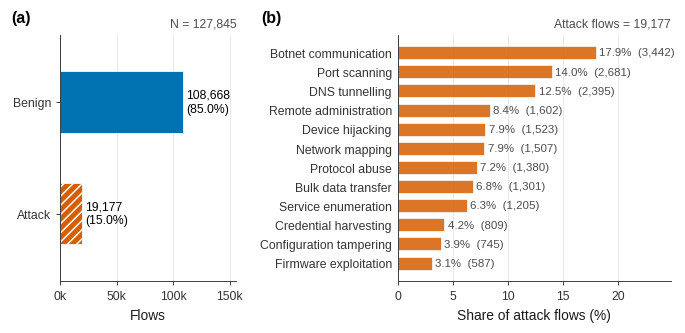

Figure 3. Composition of the frozen HITL-IoT v1.1 benchmark. (a) Binary benign–attack distribution (N = 127,845). (b) Observed distribution of the twelve generated attack families as a share of the 19,177 attack flows (counts in parentheses). Percentages are calculated directly from the canonical v1.1 dataset.


In [24]:
ATTACK_LABELS = {
    "botnet_communication": "Botnet communication", "port_scanning": "Port scanning",
    "dns_tunneling": "DNS tunnelling", "remote_administration": "Remote administration",
    "device_hijacking": "Device hijacking", "network_mapping": "Network mapping",
    "protocol_abuse": "Protocol abuse", "bulk_data_transfer": "Bulk data transfer",
    "service_enumeration": "Service enumeration", "credential_harvesting": "Credential harvesting",
    "configuration_tampering": "Configuration tampering", "firmware_exploitation": "Firmware exploitation"}

fig = plt.figure(figsize=(DOUBLE_COL, 2.9))
gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.55], wspace=0.72)

ax = fig.add_subplot(gs[0])
comp = dataset_composition.set_index("class").loc[["Benign", "Attack"]]
ypos = [1, 0]
ax.barh(ypos[0], comp.loc["Benign", "count"], color=COLORS["benign"], height=0.55, edgecolor="white")
ax.barh(ypos[1], comp.loc["Attack", "count"], color=COLORS["attack"], height=0.55, hatch=HATCH_ATTACK, edgecolor="white")
for yy, cls in zip(ypos, ["Benign", "Attack"]):
    cnt, pct = comp.loc[cls, "count"], comp.loc[cls, "percent"]
    ax.text(cnt + N * 0.02, yy, f"{cnt:,}\n({pct:.1f}%)", va="center", ha="left", fontsize=8)
ax.set_yticks(ypos, ["Benign", "Attack"])
ax.set_xlim(0, N * 1.22)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
ax.set_xlabel("Flows")
ax.set_ylim(-0.6, 1.6)
ygrid(ax, "x")
ax.text(1.0, 1.02, f"N = {N:,}", transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color=COLORS["neutral"])
panel_label(ax, "a", x=-0.28)

ax = fig.add_subplot(gs[1])
ad = attack_distribution.sort_values("count", ascending=True)
ax.barh([ATTACK_LABELS[a] for a in ad["attack_type"]], ad["percent_of_attacks"],
        color=COLORS["attack"], alpha=0.85, height=0.68, edgecolor="white")
for i, (pct, cnt) in enumerate(zip(ad["percent_of_attacks"], ad["count"])):
    ax.text(pct + 0.3, i, f"{pct:.1f}%  ({cnt:,})", va="center", fontsize=7.5, color=COLORS["neutral"])
ax.set_xlabel("Share of attack flows (%)")
ax.set_xlim(0, ad["percent_of_attacks"].max() * 1.38)
ax.xaxis.set_major_locator(MaxNLocator(5))
ax.tick_params(axis="y", length=0, pad=4)
ygrid(ax, "x")
ax.text(1.0, 1.02, f"Attack flows = {n_attack:,}", transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color=COLORS["neutral"])
panel_label(ax, "b", x=-0.50)

CAPTION_FIG3 = (f"Figure 3. Composition of the frozen HITL-IoT v1.1 benchmark. (a) Binary benign–attack distribution "
                f"(N = {N:,}). (b) Observed distribution of the twelve generated attack families as a share of the "
                f"{n_attack:,} attack flows (counts in parentheses). Percentages are calculated directly from the canonical v1.1 dataset.")
save_publication_figure(fig, "Figure3_dataset_composition", CAPTION_FIG3)
plt.show(); plt.close(fig)
print(CAPTION_FIG3)

### Figure 4 — Leakage-safe flow-feature correlation (main paper) and Figure S1 (supplementary)

Lower-triangular Pearson matrix with a diverging palette fixed at [−1, +1] and centred at 0. Only coefficients with |r| ≥ 0.50 are printed. Features keep their policy order, which groups them as packet, volume, rate, deviation, connection and historical variables; no clustering is applied.

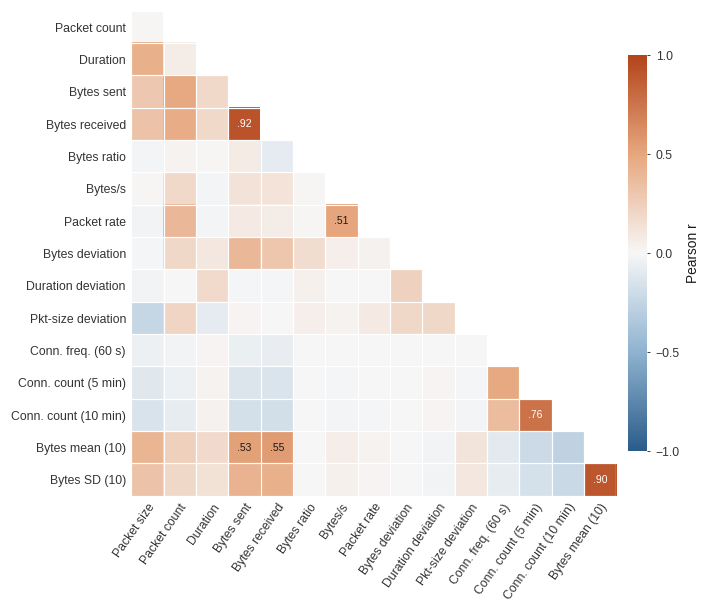

Figure 4. Pearson correlation structure among 16 representative leakage-safe Track-1 flow features in HITL-IoT v1.1 (lower triangle; N = 127,845). Features were selected from the primary flow-only feature set by a documented, label-independent rule; each rolling-window family is represented by one variant (window in flows shown in parentheses), and the complete matrix is given in supplementary Figure S1. Coefficients with |r| ≥ 0.50 are printed. Labels, benchmark-construction signals, oversight variables, destination-context variables and identifiers are excluded.


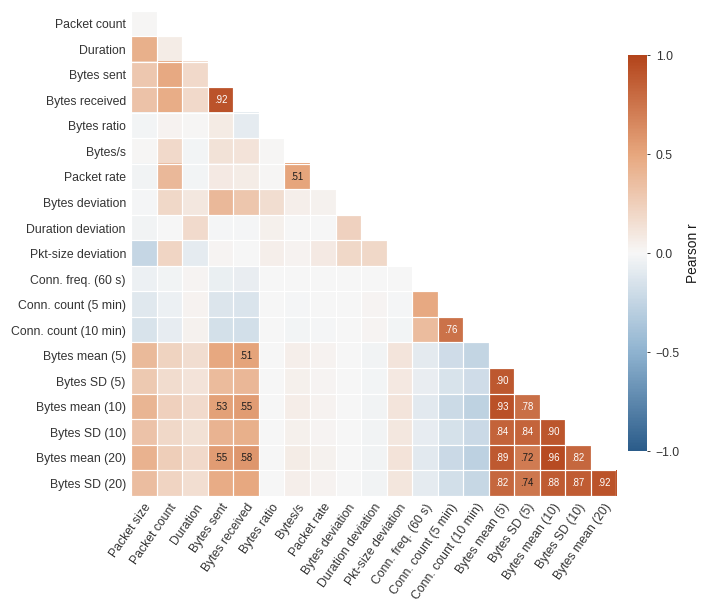

Figure S1. Complete Pearson correlation matrix of all 20 eligible leakage-safe Track-1 flow features in HITL-IoT v1.1, including every rolling-window variant (previous 5, 10 and 20 flows) (lower triangle; N = 127,845; |r| ≥ 0.50 printed).


In [25]:
SHORT = {"packet_size": "Packet size", "packet_count": "Packet count", "duration": "Duration",
         "bytes_sent": "Bytes sent", "bytes_received": "Bytes received", "bytes_ratio": "Bytes ratio",
         "bytes_per_second": "Bytes/s", "packet_rate": "Packet rate", "baseline_deviation": "Bytes deviation",
         "duration_deviation": "Duration deviation", "packet_size_deviation": "Pkt-size deviation",
         "connection_frequency": "Conn. freq. (60 s)", "connection_count_prev_5min": "Conn. count (5 min)",
         "connection_count_prev_10min": "Conn. count (10 min)",
         "bytes_sent_mean_5": "Bytes mean (5)", "bytes_sent_std_5": "Bytes SD (5)",
         "bytes_sent_mean_10": "Bytes mean (10)", "bytes_sent_std_10": "Bytes SD (10)",
         "bytes_sent_mean_20": "Bytes mean (20)", "bytes_sent_std_20": "Bytes SD (20)"}
ANNOT_THRESHOLD = 0.50

def correlation_figure(features: list[str], stem: str, caption: str, cell_in: float) -> None:
    corr = pearson_full.loc[features, features]
    k = len(features)
    data = np.ma.array(corr.to_numpy(), mask=np.triu(np.ones((k, k), dtype=bool), k=0))
    side = min(DOUBLE_COL * 0.80, cell_in * k + 1.2)
    fig, ax = plt.subplots(figsize=(side + 0.9, side))
    im = ax.imshow(data, cmap=CORR_CMAP, vmin=-1, vmax=1, interpolation="nearest")
    ax.set_xticks(range(k), [SHORT.get(c, c) for c in features], rotation=55, ha="right", rotation_mode="anchor")
    ax.set_yticks(range(k), [SHORT.get(c, c) for c in features])
    ax.set_xticks(np.arange(-0.5, k, 1), minor=True); ax.set_yticks(np.arange(-0.5, k, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.8)
    ax.tick_params(which="both", length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_xlim(-0.5, k - 1.5); ax.set_ylim(k - 0.5, 0.5)
    for i in range(k):
        for j in range(i):
            r = corr.iat[i, j]
            if abs(r) >= ANNOT_THRESHOLD:
                ax.text(j, i, f"{r:.2f}".replace("0.", ".").replace("-.", "−."), ha="center", va="center",
                        fontsize=6.8 if k <= 16 else 6.3, color="white" if abs(r) > 0.75 else "#1A1A1A")
    cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02, ticks=[-1, -0.5, 0, 0.5, 1])
    cb.set_label("Pearson r"); cb.outline.set_visible(False); cb.ax.tick_params(length=2)
    save_publication_figure(fig, stem, caption)
    plt.show(); plt.close(fig)

CAPTION_FIG4 = (f"Figure 4. Pearson correlation structure among {len(corr_features)} representative leakage-safe Track-1 flow "
                f"features in HITL-IoT v1.1 (lower triangle; N = {N:,}). Features were selected from the primary flow-only feature "
                f"set by a documented, label-independent rule; each rolling-window family is represented by one variant "
                f"(window in flows shown in parentheses), and the complete matrix is given in supplementary Figure S1. "
                f"Coefficients with |r| ≥ {ANNOT_THRESHOLD:.2f} are printed. Labels, benchmark-construction signals, oversight "
                f"variables, destination-context variables and identifiers are excluded.")
CAPTION_FIGS1 = (f"Figure S1. Complete Pearson correlation matrix of all {len(corr_features_full)} eligible leakage-safe Track-1 flow "
                 f"features in HITL-IoT v1.1, including every rolling-window variant (previous 5, 10 and 20 flows) "
                 f"(lower triangle; N = {N:,}; |r| ≥ {ANNOT_THRESHOLD:.2f} printed).")
correlation_figure(corr_features, "Figure4_flow_feature_correlation", CAPTION_FIG4, cell_in=0.36)
print(CAPTION_FIG4)
correlation_figure(corr_features_full, "FigureS1_flow_feature_correlation_full", CAPTION_FIGS1, cell_in=0.34)
print(CAPTION_FIGS1)

### Figure 5 — Temporal structure and chronological evaluation boundaries

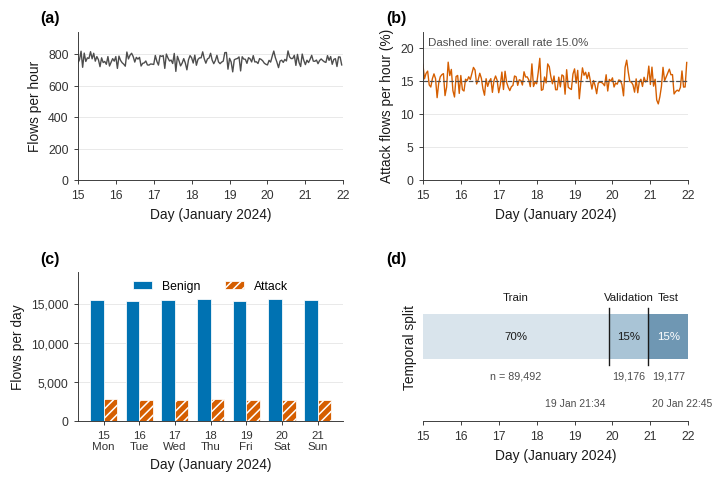

Figure 5. Temporal structure of HITL-IoT v1.1 over the seven-day generation window. (a) Generated flows per clock hour. (b) Attack share per clock hour; the dashed line marks the overall attack rate (15.0%). (c) Daily benign and attack counts. (d) Chronological boundaries of the primary 70/15/15 temporal evaluation protocol (train/validation/test). Timestamps are generated independently of class; a χ² test of class × hour of day gives χ²(23) = 22.7, p = 0.480. The secondary IID split has no chronological meaning and is not shown.


In [26]:
hc = df.groupby("clock_hour")["is_attack"].agg(flows="size", attacks="sum")
hc["rate"] = 100 * hc["attacks"] / hc["flows"]
overall_rate = 100 * n_attack / N
dc = df.groupby("date")["is_attack"].agg(flows="size", attacks="sum")
dc["benign"] = dc["flows"] - dc["attacks"]
t0, t1 = df["timestamp"].min().floor("D"), df["timestamp"].max().ceil("D")
day_fmt = mdates.DateFormatter("%d")

fig, axes = plt.subplots(2, 2, figsize=(DOUBLE_COL, 4.6))
fig.subplots_adjust(hspace=0.62, wspace=0.30)

ax = axes[0, 0]
ax.plot(hc.index, hc["flows"], color=COLORS["neutral"], lw=0.9)
ax.set_ylabel("Flows per hour"); ax.set_xlabel("Day (January 2024)")
ax.set_ylim(0, hc["flows"].max() * 1.15); ax.yaxis.set_major_formatter(thousands)
ax.set_xlim(t0, t1); ax.xaxis.set_major_locator(mdates.DayLocator()); ax.xaxis.set_major_formatter(day_fmt)
ygrid(ax); panel_label(ax, "a")

ax = axes[0, 1]
ax.plot(hc.index, hc["rate"], color=COLORS["attack"], lw=0.9)
ax.axhline(overall_rate, color=COLORS["neutral"], lw=0.8, ls="--")
ax.text(t0 + pd.Timedelta(hours=3), hc["rate"].max() * 1.13, f"Dashed line: overall rate {overall_rate:.1f}%",
        va="center", ha="left", fontsize=7.5, color=COLORS["neutral"])
ax.set_ylabel("Attack flows per hour (%)"); ax.set_xlabel("Day (January 2024)")
ax.set_ylim(0, hc["rate"].max() * 1.22)
ax.set_xlim(t0, t1); ax.xaxis.set_major_locator(mdates.DayLocator()); ax.xaxis.set_major_formatter(day_fmt)
ygrid(ax); panel_label(ax, "b")

ax = axes[1, 0]
x = np.arange(len(dc)); wbar = 0.38
ax.bar(x - wbar / 2, dc["benign"], wbar, color=COLORS["benign"], label="Benign", edgecolor="white")
ax.bar(x + wbar / 2, dc["attacks"], wbar, color=COLORS["attack"], hatch=HATCH_ATTACK, label="Attack", edgecolor="white")
ax.set_xticks(x, [pd.Timestamp(d).strftime("%d\n%a") for d in dc.index], fontsize=7.5)
ax.set_ylabel("Flows per day"); ax.set_xlabel("Day (January 2024)")
ax.yaxis.set_major_formatter(thousands); ax.set_ylim(0, dc["benign"].max() * 1.22)
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))
ygrid(ax); panel_label(ax, "c")

ax = axes[1, 1]
tsb = split_boundaries[split_boundaries.protocol == "temporal"].set_index("split")
edges = [t0, tsb.loc["validation", "first_timestamp"], tsb.loc["test", "first_timestamp"], t1]
for (part, a_, b_) in zip(["train", "validation", "test"], edges[:-1], edges[1:]):
    ax.axvspan(a_, b_, ymin=0.42, ymax=0.72, color=SPLIT_COLORS[part], lw=0)
    mid = a_ + (b_ - a_) / 2
    ax.text(mid, 0.80, part.capitalize(), ha="center", va="bottom", fontsize=7.5, color="#1A1A1A")
    ax.text(mid, 0.57, f"{tsb.loc[part, 'proportion']*100:.0f}%", ha="center", va="center", fontsize=7.5,
            color="#1A1A1A" if part != "test" else "white")
    ax.text(mid, 0.34, f"n = {int(tsb.loc[part, 'flows']):,}" if part == "train" else f"{int(tsb.loc[part, 'flows']):,}",
            ha="center", va="top", fontsize=7, color=COLORS["neutral"])
for b, ha, off in ((edges[1], "right", -1), (edges[2], "left", 1)):
    ax.axvline(b, ymin=0.38, ymax=0.76, color="#1A1A1A", lw=0.9)
    ax.text(b + pd.Timedelta(hours=2 * off), 0.12, b.strftime("%d Jan %H:%M"), ha=ha, va="center", fontsize=6.8,
            color=COLORS["neutral"])
ax.set_ylim(0, 1); ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlim(t0, t1); ax.xaxis.set_major_locator(mdates.DayLocator()); ax.xaxis.set_major_formatter(day_fmt)
ax.set_xlabel("Day (January 2024)"); ax.set_ylabel("Temporal split")
panel_label(ax, "d")

chi_hour = temporal_tests.set_index("test").loc["class × hour_of_day"]
CAPTION_FIG5 = (f"Figure 5. Temporal structure of HITL-IoT v1.1 over the seven-day generation window. (a) Generated flows per "
                f"clock hour. (b) Attack share per clock hour; the dashed line marks the overall attack rate ({overall_rate:.1f}%). "
                f"(c) Daily benign and attack counts. (d) Chronological boundaries of the primary 70/15/15 temporal evaluation "
                f"protocol (train/validation/test). Timestamps are generated independently of class; a χ² test of class × hour of "
                f"day gives χ²({int(chi_hour['dof'])}) = {chi_hour['chi2']:.1f}, p = {chi_hour['p_value']:.3f}. "
                f"The secondary IID split has no chronological meaning and is not shown.")
save_publication_figure(fig, "Figure5_temporal_patterns", CAPTION_FIG5)
plt.show(); plt.close(fig)
print(CAPTION_FIG5)

### Figure 6 — Controlled ambiguity and the Top-K oversight subset

Panel (a) uses empirical cumulative distribution functions (ECDFs) to avoid overlapping histograms. Panel (c) uses ECDFs on a logarithmic byte axis because byte volumes are heavy-tailed; line colour encodes class and line style encodes population. Panel (d) shows box plots with all points beyond the whiskers retained.

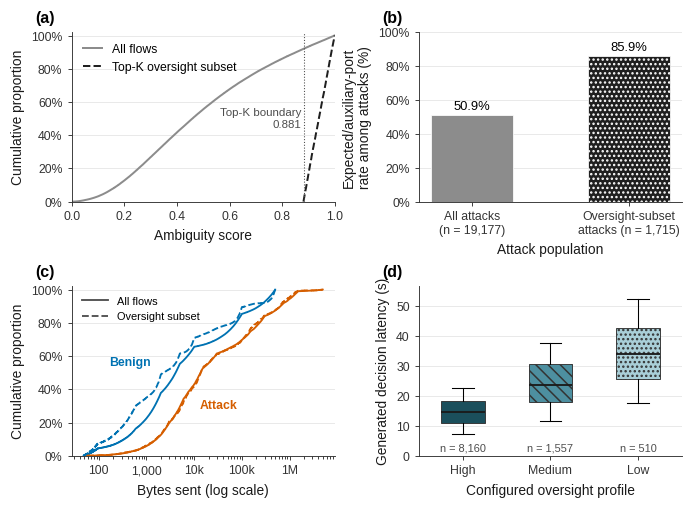

Figure 6. Controlled ambiguity and configured oversight characteristics in HITL-IoT v1.1. (a) Empirical cumulative distribution function (ECDF) of the ambiguity score for all flows (N = 127,845) and the Top-K oversight subset (K = 10,227); the dotted line marks the minimum ambiguity among selected flows. (b) Expected/auxiliary destination-port rate (device service ports plus DNS/NTP) among all attacks and among attacks in the oversight subset; this observed rate is distinct from the configured attack-specific mimicry probability. (c) ECDFs of bytes sent (logarithmic axis) for benign (blue) and attack (orange) flows in the full dataset (solid) and the oversight subset (dashed). (d) Generated decision-latency distributions for the three configured oversight profiles (boxes: interquartile range; line: median; whiskers: 1.5 × IQR; circles: points beyond the whiskers). Profiles are generator configurations, not security analysts.


In [27]:
def ecdf(x):
    x = np.sort(np.asarray(x, dtype=float))
    return x, np.arange(1, x.size + 1) / x.size

fig, axes = plt.subplots(2, 2, figsize=(DOUBLE_COL, 5.0))
fig.subplots_adjust(hspace=0.50, wspace=0.32)

ax = axes[0, 0]
for key, frame in (("full", df), ("oversight", sel)):
    xx, yy = ecdf(frame["ambiguity_score"])
    ax.step(xx, yy, where="post", color=COLORS[key], ls=LINESTYLES[key], lw=1.3,
            label="All flows" if key == "full" else "Top-K oversight subset")
ax.axvline(MIN_SELECTED, color=COLORS["neutral"], lw=0.7, ls=":")
ax.text(MIN_SELECTED - 0.01, 0.50, f"Top-K boundary\n{MIN_SELECTED:.3f}", ha="right", va="center", fontsize=7.5, color=COLORS["neutral"])
ax.set_xlabel("Ambiguity score"); ax.set_ylabel("Cumulative proportion")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.legend(loc="upper left"); ygrid(ax); panel_label(ax, "a")

ax = axes[0, 1]
sel_att = sel[sel["is_attack"]]
vals = [100 * attacks["port_expected_for_device"].mean(), 100 * sel_att["port_expected_for_device"].mean()]
ns = [len(attacks), len(sel_att)]
labels = [f"All attacks\n(n = {ns[0]:,})", f"Oversight-subset\nattacks (n = {ns[1]:,})"]
bars = ax.bar([0, 1], vals, width=0.52, color=[COLORS["full"], COLORS["oversight"]], edgecolor="white")
bars[1].set_hatch("....")
for i, (v, n_) in enumerate(zip(vals, ns)):
    ax.text(i, v + 1.5, f"{v:.1f}%", ha="center", va="bottom", fontsize=8.5)
ax.set_xticks([0, 1], labels); ax.set_ylim(0, 100)
ax.set_ylabel("Expected/auxiliary-port\nrate among attacks (%)"); ax.set_xlabel("Attack population")
ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ygrid(ax); panel_label(ax, "b")

ax = axes[1, 0]
for key, frame in (("full", df), ("oversight", sel)):
    for cls, is_att in (("benign", False), ("attack", True)):
        xx, yy = ecdf(frame.loc[frame["is_attack"] == is_att, "bytes_sent"])
        ax.step(xx, yy, where="post", color=COLORS[cls], ls=LINESTYLES[key], lw=1.2,
                label=f"{cls.capitalize()} — {'all flows' if key == 'full' else 'oversight subset'}")
ax.set_xscale("log")
ax.set_xlabel("Bytes sent (log scale)"); ax.set_ylabel("Cumulative proportion")
ax.set_ylim(0, 1.02); ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}" if v < 1e4 else f"{v/1e3:,.0f}k" if v < 1e6 else f"{v/1e6:,.0f}M"))
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color=COLORS["neutral"], ls=LINESTYLES["full"], lw=1.2, label="All flows"),
                   Line2D([], [], color=COLORS["neutral"], ls=LINESTYLES["oversight"], lw=1.2, label="Oversight subset")],
          loc="upper left", fontsize=7.2, handlelength=2.4)
b_med = df.loc[~df["is_attack"], "bytes_sent"].median()
a_q = df.loc[df["is_attack"], "bytes_sent"].quantile(0.30)
ax.text(b_med / 3.4, 0.56, "Benign", color=COLORS["benign"], ha="right", va="center", fontsize=8, fontweight="bold")
ax.text(a_q * 2.6, 0.30, "Attack", color=COLORS["attack"], ha="left", va="center", fontsize=8, fontweight="bold")
ygrid(ax); panel_label(ax, "c")

ax = axes[1, 1]
lat = [ov.loc[ov["oversight_profile"] == p, "generated_decision_latency"].to_numpy() for p in PROFILE_ORDER]
bp = ax.boxplot(lat, positions=[0, 1, 2], widths=0.5, patch_artist=True,
                medianprops=dict(color="#1A1A1A", lw=1.2), whiskerprops=dict(lw=0.7), capprops=dict(lw=0.7),
                flierprops=dict(marker="o", markersize=1.8, markerfacecolor="none", markeredgecolor="#777777", markeredgewidth=0.4))
for patch, p, h in zip(bp["boxes"], PROFILE_ORDER, ["", "\\\\\\", "...."]):
    patch.set_facecolor(COLORS[p]); patch.set_edgecolor("#333333"); patch.set_linewidth(0.6); patch.set_hatch(h)
for i, p in enumerate(PROFILE_ORDER):
    n_p = int((ov["oversight_profile"] == p).sum())
    ax.text(i, 1.5, f"n = {n_p:,}", ha="center", fontsize=7.2, color=COLORS["neutral"])
ax.set_xticks([0, 1, 2], [PROFILE_LABELS[p] for p in PROFILE_ORDER])
ax.set_xlabel("Configured oversight profile"); ax.set_ylabel("Generated decision latency (s)")
ax.set_ylim(0, max(np.max(a) for a in lat) * 1.08)
ygrid(ax); panel_label(ax, "d")

CAPTION_FIG6 = (f"Figure 6. Controlled ambiguity and configured oversight characteristics in HITL-IoT v1.1. (a) Empirical cumulative "
                f"distribution function (ECDF) of the ambiguity score for all flows (N = {N:,}) and the Top-K oversight subset "
                f"(K = {len(sel):,}); the dotted line marks the minimum ambiguity among selected flows. (b) Expected/auxiliary "
                f"destination-port rate (device service ports plus DNS/NTP) among all attacks and among attacks in the "
                f"oversight subset; this observed rate is distinct from the configured attack-specific mimicry probability. (c) ECDFs of bytes sent (logarithmic axis) "
                f"for benign (blue) and attack (orange) flows in the full dataset (solid) and the oversight subset (dashed). (d) Generated "
                f"decision-latency distributions for the three configured oversight profiles (boxes: interquartile range; line: "
                f"median; whiskers: 1.5 × IQR; circles: points beyond the whiskers). Profiles are generator configurations, not "
                f"security analysts.")
save_publication_figure(fig, "Figure6_controlled_ambiguity", CAPTION_FIG6)
plt.show(); plt.close(fig)
print(CAPTION_FIG6)

## 17. Exported Manuscript Values

All manuscript-relevant numbers are collected from the computed tables above into one machine-readable JSON file. Nothing is typed by hand.

In [28]:
def jsonable(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (pd.Timestamp,)): return o.isoformat()
    return str(o)

manuscript = {
    "source": {"release": manifest["dataset_name"] + " " + manifest["version"], "seed": manifest["seed"],
               "dataset_sha256": ds_row["Observed SHA-256"], "generator_environment": manifest["environment"]},
    "dataset": to_records(dataset_composition, "class"),
    "devices": to_records(device_distribution, "device_type"),
    "attacks": to_records(attack_distribution, "attack_type"),
    "protocols": to_records(protocol_distribution, "protocol"),
    "services": {"n_categories": int(df["service_category"].nunique()),
                 "overall": to_records(service_distribution, "service_category"),
                 "by_class": to_records(service_distribution_by_class, "service_category")},
    "destination_categories": to_records(destination_distribution, "dst_category"),
    "expected_port_rate": {"table": to_records(attack_expected_port_rate, "attack_type"),
                           "note": "Observed expected/auxiliary destination-port rate; not the configured mimicry probability."},
    "continuous_features": {v: to_records(continuous_statistics[continuous_statistics.variable == v].drop(columns="variable"), "group")
                            for v in CONT_VARS},
    "ambiguity": {"by_group": to_records(ambiguity_statistics.head(5), "group"),
                  "min_selected": MIN_SELECTED, "max_unselected": MAX_UNSELECTED, "top_k_property": TOPK_OK},
    "oversight_subset": {"full_vs_oversight": to_records(full_vs_oversight, "metric"),
                         "model_profile_agreement": to_records(model_profile_agreement.assign(key=model_profile_agreement.level + ":" + model_profile_agreement.group).drop(columns=["level", "group"]), "key"),
                         "disagreement_detail": dis_detail,
                         "construction_diagnostics": to_records(construction_diagnostics, "population")},
    "profiles": {"configuration": to_records(oversight_profile_configuration, "oversight_profile"),
                 "distribution": to_records(oversight_profile_distribution, "oversight_profile"),
                 "performance": to_records(oversight_profile_performance, "oversight_profile"),
                 "confidence": to_records(profile_confidence_statistics, "oversight_profile"),
                 "latency": to_records(profile_latency_statistics, "oversight_profile"),
                 "note": "Configured/generated oversight profiles; not measurements of security analysts."},
    "temporal": {"daily": to_records(daily, "period"), "hour_of_day": to_records(hour_of_day, "period"),
                 "weekday_weekend": to_records(weekpart, "period"),
                 "independence_tests": to_records(temporal_tests, "test"),
                 "splits": to_records(split_boundaries.assign(key=split_boundaries.protocol + ":" + split_boundaries.split).drop(columns=["protocol", "split"]), "key")},
    "figure4": {"main_features": corr_features, "supplementary_features": corr_features_full,
                "rolling_family_representatives": representatives, "annotation_threshold_abs_r": ANNOT_THRESHOLD},
    "captions": {"Figure3": CAPTION_FIG3, "Figure4": CAPTION_FIG4, "Figure5": CAPTION_FIG5, "Figure6": CAPTION_FIG6,
                 "FigureS1": CAPTION_FIGS1},
}
MANUSCRIPT_JSON = DIRS["manuscript_values"] / "manuscript_descriptive_statistics.json"
MANUSCRIPT_JSON.write_text(json.dumps(manuscript, indent=2, default=jsonable, ensure_ascii=False), encoding="utf-8")
json.loads(MANUSCRIPT_JSON.read_text(encoding="utf-8"))  # round-trip check
print(f"Written {MANUSCRIPT_JSON} ({MANUSCRIPT_JSON.stat().st_size/1024:.1f} KB), sections: {list(manuscript)}")

Written analysis_v1.1/manuscript_values/manuscript_descriptive_statistics.json (53.6 KB), sections: ['source', 'dataset', 'devices', 'attacks', 'protocols', 'services', 'destination_categories', 'expected_port_rate', 'continuous_features', 'ambiguity', 'oversight_subset', 'profiles', 'temporal', 'figure4', 'captions']


## 18. Reproducibility and Integrity Summary

### 18.1 Cross-check against the release summary

Notebook-computed values are compared with the generator's own `HITL-IoT_summary_v1.1.json`.

In [29]:
cross = []
def xcheck(name, notebook_value, summary_value):
    cross.append({"quantity": name, "notebook": notebook_value, "release_summary": summary_value,
                  "result": "PASS" if notebook_value == summary_value else "FAIL"})

xcheck("total rows", N, summary["dataset"]["rows"])
xcheck("benign count", n_benign, summary["class_distribution"]["benign"]["count"])
xcheck("attack count", n_attack, summary["class_distribution"]["attack"]["count"])
for d, row in device_distribution.set_index("device_type").iterrows():
    xcheck(f"device count: {d}", int(row["count"]), summary["device_distribution"][d]["count"])
for a, row in attack_distribution.set_index("attack_type").iterrows():
    xcheck(f"attack count: {a}", int(row["count"]), summary["attack_distribution_observed"][a]["count"])
xcheck("oversight count", len(ov), summary["oversight_subset"]["selected_count"])
for p in PROFILE_ORDER:
    xcheck(f"profile count: {p}", int((ov.oversight_profile == p).sum()), summary["oversight_subset"]["profiles"][p]["count"])
cross_check = pd.DataFrame(cross)
save_table(cross_check, "summary_cross_check.csv", "audit")
assert (cross_check["result"] == "PASS").all(), cross_check[cross_check.result == "FAIL"]
print(f"Cross-check against release summary: {len(cross_check)} quantities, all PASS")

Cross-check against release summary: 24 quantities, all PASS


### 18.2 Figure Quality Control

Machine-checkable properties are tested automatically. An axis counts as labelled if it has an axis title or, for matrix panels such as the correlation heatmap, named categorical tick labels on both axes. Visual quality (readability, balance, greyscale legibility) cannot be verified by code and is listed separately as a manual checklist.

In [30]:
REQUIRED_FIGS = ["Figure3_dataset_composition", "Figure4_flow_feature_correlation",
                 "Figure5_temporal_patterns", "Figure6_controlled_ambiguity", "FigureS1_flow_feature_correlation_full"]
OBSOLETE = [r"human annotation", r"human confidence", r"human response time", r"ml[- ]human agreement",
            r"realistic ambiguity", r"status:\s*realistic", r"compliant", r"the only dataset", r"perfect reproducibility",
            r"real analysts?", r"ml_confidence", r"risk_score", r"mixed/unknown", r"realism validation",
            r"port[- ]mimicry", r"mimicry \(%\)"]
qc_rows, fig_ok = [], {}
for stem in REQUIRED_FIGS:
    info = FIGURE_REGISTRY.get(stem)
    checks = {}
    checks["registered"] = info is not None
    if info:
        p = info["paths"]
        checks["pdf_nonempty"] = p["pdf"].is_file() and p["pdf"].stat().st_size > 5_000 and p["pdf"].read_bytes()[:4] == b"%PDF"
        checks["svg_nonempty"] = p["svg"].is_file() and p["svg"].stat().st_size > 5_000 and b"<svg" in p["svg"].read_bytes()[:2000]
        img = plt.imread(p["png"])
        h, w_ = img.shape[:2]
        checks["png_resolution"] = w_ / info["size_in"][0] >= 290 and w_ >= 1500
        # An axis passes if it has an axis title, or (matrix/heatmap panels) named categorical tick labels on both axes.
        checks["axes_labelled"] = all((a["xlabel"] or a["ylabel"]) or
                                      (a["xticklabels"] and a["yticklabels"] and
                                       not any(re.fullmatch(r"[−\-\d.,%k ]+", t) for t in a["xticklabels"] + a["yticklabels"]))
                                      for a in info["axes"])
        text_blob = " ".join([info["caption"]] + [a["xlabel"] + " " + a["ylabel"] + " " + " ".join(a["texts"]) for a in info["axes"]]).lower()
        checks["no_obsolete_terms"] = not any(re.search(t, text_blob) for t in OBSOLETE)
        checks["png_px"] = f"{w_}×{h}"
    ok = all(v for k2, v in checks.items() if k2 != "png_px")
    fig_ok[stem] = ok
    qc_rows.append({"figure": stem, **checks, "result": "PASS" if ok else "FAIL"})
figure_qc = pd.DataFrame(qc_rows)
save_table(figure_qc, "figure_quality_control.csv", "audit")
for stem in REQUIRED_FIGS:
    print(f"{stem.split('_')[0].replace('Figure', 'Figure ')}: {'PASS' if fig_ok[stem] else 'FAIL'}")
VECTOR_OK = bool(figure_qc["pdf_nonempty"].all() and figure_qc["svg_nonempty"].all())
RASTER_OK = bool(figure_qc["png_resolution"].all())
print(f"\nVector exports (PDF/SVG): {'PASS' if VECTOR_OK else 'FAIL'}")
print(f"High-resolution raster exports (≥300 dpi at design size): {'PASS' if RASTER_OK else 'FAIL'}")
print("Shared style system: applied programmatically via set_publication_style() — visual consistency requires manual review.")
FIGURES_OK = all(fig_ok.values())
figure_qc

Figure 3: PASS
Figure 4: PASS
Figure 5: PASS
Figure 6: PASS
Figure S1: PASS

Vector exports (PDF/SVG): PASS
High-resolution raster exports (≥300 dpi at design size): PASS
Shared style system: applied programmatically via set_publication_style() — visual consistency requires manual review.


,figure,registered,pdf_nonempty,svg_nonempty,png_resolution,axes_labelled,no_obsolete_terms,png_px,result
0,Figure3_dataset_composition,True,True,True,True,True,True,3652×1724,PASS
1,Figure4_flow_feature_correlation,True,True,True,True,True,True,3783×3257,PASS
2,Figure5_temporal_patterns,True,True,True,True,True,True,3848×2554,PASS
3,Figure6_controlled_ambiguity,True,True,True,True,True,True,3688×2678,PASS
4,FigureS1_flow_feature_correlation_full,True,True,True,True,True,True,3783×3257,PASS


In [31]:
print("MANUAL FIGURE REVIEW BEFORE SUBMISSION\n")
for item in ["All text is readable at final journal width.", "Panel labels are consistent.",
             "No legend obscures data.", "Colors remain distinguishable in grayscale.",
             "Axis labels include units where applicable.", "No misleading axis truncation.",
             "No unsupported realism/compliance language.", "PDF/SVG opens correctly.",
             "PNG resolution is sufficient.", "Captions match the plotted data.",
             "Figure numbers match manuscript numbering."]:
    print(f"[ ] {item}")

MANUAL FIGURE REVIEW BEFORE SUBMISSION

[ ] All text is readable at final journal width.
[ ] Panel labels are consistent.
[ ] No legend obscures data.
[ ] Colors remain distinguishable in grayscale.
[ ] Axis labels include units where applicable.
[ ] No misleading axis truncation.
[ ] No unsupported realism/compliance language.
[ ] PDF/SVG opens correctly.
[ ] PNG resolution is sufficient.
[ ] Captions match the plotted data.
[ ] Figure numbers match manuscript numbering.


## 19. Key Findings for Manuscript Revision

The statements below are assembled programmatically from the computed values, so they update automatically if the notebook is rerun on a different verified release. They describe the generated benchmark only.

In [32]:
perf_i = oversight_profile_performance.set_index("oversight_profile")
fvo = full_vs_oversight.set_index("metric")
cd = construction_diagnostics.set_index("population")
chi_day = temporal_tests.set_index("test").loc["class × day"]
findings = [
    f"Composition: {N:,} generated flows — {n_benign:,} benign ({100*n_benign/N:.2f}%) and {n_attack:,} attack ({100*n_attack/N:.2f}%) — "
    f"across five device types ({', '.join(f'{d} {p:.2f}%' for d, p in device_distribution.set_index('device_type')['percent'].items())}). "
    f"No Mixed/Unknown category exists in v1.1; the legacy Table 2 percentages must be replaced.",
    f"Attack families: {attack_distribution.iloc[0]['attack_type']} is the largest family ({attack_distribution.iloc[0]['percent_of_attacks']:.2f}% of attacks); "
    f"{attack_distribution.iloc[-1]['attack_type']} the smallest ({attack_distribution.iloc[-1]['percent_of_attacks']:.2f}%). Observed shares match the "
    f"configured proportions to within {abs(attack_distribution['percent_of_attacks'] - attack_distribution['configured_percent']).max():.3f} percentage points.",
    f"Transport protocol: UDP accounts for {protocol_distribution.set_index('protocol').loc['UDP', 'benign_percent']:.2f}% of benign and "
    f"{protocol_distribution.set_index('protocol').loc['UDP', 'attack_percent']:.2f}% of attack flows, so transport protocol is not a class shortcut.",
    f"Expected/auxiliary-port rate: {EXPECTED_PORT_RATE_ALL:.2f}% of attacks use a device service port or a benign auxiliary port "
    f"(DNS/NTP), rising to {fvo.loc['expected_or_auxiliary_port_rate_among_attacks_percent', 'oversight_subset']:.2f}% among oversight-subset "
    f"attacks: ambiguity selection favours attacks on ordinary-looking service ports. This observed rate must not be equated with the "
    f"configured mimicry probability.",
    f"Controlled ambiguity: the Top-K subset holds {len(sel):,} flows ({100*len(sel)/N:.3f}%) with ambiguity ≥ {MIN_SELECTED:.4f} "
    f"(median {fvo.loc['ambiguity_median', 'oversight_subset']:.4f} vs {fvo.loc['ambiguity_median', 'full_dataset']:.4f} overall).",
    f"Benchmark construction diagnostic (not an ML result): generated construction-prediction accuracy is "
    f"{100*cd.loc['full_dataset', 'generated_construction_prediction_accuracy']:.2f}% on all flows and "
    f"{100*cd.loc['oversight_subset', 'generated_construction_prediction_accuracy']:.2f}% on the oversight subset. Trained-classifier accuracy "
    f"belongs to the Track-1 experiment.",
    f"Class balance in the oversight subset: attack rate {fvo.loc['attack_rate_percent', 'oversight_subset']:.2f}%, so the majority-class baseline "
    f"reaches {100*perf_i.loc['majority_class_baseline', 'accuracy']:.2f}% accuracy with 50% balanced accuracy.",
    "Configured profiles (not analysts): accuracy / balanced accuracy — " +
    "; ".join(f"{PROFILE_LABELS[p]} {100*perf_i.loc[p, 'accuracy']:.2f}% / {100*perf_i.loc[p, 'balanced_accuracy']:.2f}%" for p in PROFILE_ORDER) +
    f". The high-competence profile's accuracy is {'below' if perf_i.loc['high_competence','accuracy'] < perf_i.loc['majority_class_baseline','accuracy'] else 'at or above'} "
    f"the majority-class baseline; balanced accuracy should be the headline metric.",
    f"Model–profile agreement: {100*model_profile_agreement.iloc[0]['agreement_rate']:.2f}% overall; within {dis_detail['disagreements']:,} disagreements "
    f"the profile decision is correct in {dis_detail['profile_decision_correct']:,} and the generated prediction in {dis_detail['generated_prediction_correct']:,}.",
    f"Temporal: flows and attacks are spread evenly over the seven days by construction (χ² class × day = {chi_day['chi2']:.1f}, "
    f"p = {chi_day['p_value']:.3f}). The temporal split is therefore methodologically conservative but does not introduce distribution drift.",
]
for i, f_ in enumerate(findings, 1):
    print(f"{i}. {f_}\n")

1. Composition: 127,845 generated flows — 108,668 benign (85.00%) and 19,177 attack (15.00%) — across five device types (camera 20.00%, thermostat 20.00%, speaker 20.00%, doorbell 20.00%, tv 20.00%). No Mixed/Unknown category exists in v1.1; the legacy Table 2 percentages must be replaced.

2. Attack families: botnet_communication is the largest family (17.95% of attacks); firmware_exploitation the smallest (3.06%). Observed shares match the configured proportions to within 0.003 percentage points.

3. Transport protocol: UDP accounts for 20.33% of benign and 20.34% of attack flows, so transport protocol is not a class shortcut.

4. Expected/auxiliary-port rate: 50.92% of attacks use a device service port or a benign auxiliary port (DNS/NTP), rising to 85.89% among oversight-subset attacks: ambiguity selection favours attacks on ordinary-looking service ports. This observed rate must not be equated with the configured mimicry probability.

5. Controlled ambiguity: the Top-K subset hold

## 20. Final Report

In [33]:
expected_tables = ["dataset_composition.csv", "device_distribution.csv", "attack_distribution.csv", "protocol_distribution.csv",
                   "service_distribution.csv", "service_distribution_by_class.csv", "destination_distribution.csv",
                   "attack_expected_port_rate.csv", "continuous_statistics.csv", "ambiguity_statistics.csv", "full_vs_oversight.csv",
                   "oversight_profile_distribution.csv", "oversight_profile_performance.csv", "profile_confidence_statistics.csv",
                   "profile_latency_statistics.csv", "temporal_statistics.csv"]
TABLES_OK = all((DIRS["tables"] / t).is_file() for t in expected_tables)
AUDIT_OK = all((DIRS["audit"] / t).is_file() for t in ("variable_audit.csv", "source_verification.csv"))
JSON_OK = MANUSCRIPT_JSON.is_file()
P = lambda b: "PASS" if b else "FAIL"
bar = "=" * 60
print(bar); print("HITL-IoT v1.1 DESCRIPTIVE ANALYSIS COMPLETE"); print(bar)
print(f"\nSource release verified: {P(SOURCE_VERIFIED)}")
print(f"Dataset rows: {N:,}")
print(f"Benign: {n_benign:,} ({100*n_benign/N:.2f}%)")
print(f"Attack: {n_attack:,} ({100*n_attack/N:.2f}%)")
print(f"Device taxonomy: {df['device_type'].nunique()} types, {device_distribution['percent'].sum():.0f}% accounted for")
print(f"Attack taxonomy: {n_attack_families} categories")
print(f"Oversight subset: {len(ov):,}")
print(f"Top-K ambiguity property: {P(TOPK_OK)}")
print(f"Configured-profile ordering (high > medium > low accuracy): {P(PROFILE_ORDERING_OK)}")
print(f"Summary cross-check: {P((cross_check.result == 'PASS').all())}")
print(f"Variable audit exported: {P(VARIABLE_AUDIT_OK and AUDIT_OK)}")
print(f"Tables exported: {P(TABLES_OK)} ({len(set(TABLES_WRITTEN))} files)")
print(f"Figures 3–6 + S1 exported: {P(FIGURES_OK)}")
print(f"Manuscript JSON exported: {P(JSON_OK)}")
print(f"\nOutputs written to:\n{OUT_DIR}/")
print(bar)

HITL-IoT v1.1 DESCRIPTIVE ANALYSIS COMPLETE

Source release verified: PASS
Dataset rows: 127,845
Benign: 108,668 (85.00%)
Attack: 19,177 (15.00%)
Device taxonomy: 5 types, 100% accounted for
Attack taxonomy: 12 categories
Oversight subset: 10,227
Top-K ambiguity property: PASS
Configured-profile ordering (high > medium > low accuracy): PASS
Summary cross-check: PASS
Variable audit exported: PASS
Tables exported: PASS (28 files)
Figures 3–6 + S1 exported: PASS
Manuscript JSON exported: PASS

Outputs written to:
analysis_v1.1/
